# Step 1 – Load the Spambase Dataset

In this step, I will load the Spambase dataset from the UCI Machine Learning Repository into Google Colab using Python. This dataset contains 4,601 email records and 57 numerical features that describe characteristics of each email.

My goal is to examine the dataset's structure and understand how the data is organized before performing any analysis or building a classification model.

4,601 rows: Each row represents one email.

58 columns: The first 57 columns are numerical features extracted from emails.

Column 57: This is the target variable, indicating whether an email is spam (1) or ham (0).

Column names: Currently displayed as numbers because we have not assigned meaningful feature names.

In [2]:
# Step 1: Load the Spambase Dataset

import pandas as pd

# URL of the UCI Spambase dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.data"

# Load the dataset
spam_df = pd.read_csv(url, header=None)

# Display the dataset dimensions
print("Dataset Shape:", spam_df.shape)

# Display the first five records
print("\nFirst 5 Rows:")
display(spam_df.head())

Dataset Shape: (4601, 58)

First 5 Rows:


,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,57
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


# Step 2a: Reading features from UCI

In this step, I will read the official spambase.names documentation file from the UCI Machine Learning Repository and automatically extract the feature names.

Instead of manually entering all 57 feature names, I will use Python to identify and extract them directly from the documentation.

My goal is to understand how to use dataset metadata to assign meaningful column names, making the dataset easier to explore and analyze.

In [3]:
# Read the official feature documentation from UCI

names_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.names"

import requests

response = requests.get(names_url)
response.raise_for_status()

# Display the documentation
print(response.text)

| SPAM E-MAIL DATABASE ATTRIBUTES (in .names format)
|
| 48 continuous real [0,100] attributes of type word_freq_WORD 
| = percentage of words in the e-mail that match WORD,
| i.e. 100 * (number of times the WORD appears in the e-mail) / 
| total number of words in e-mail.  A "word" in this case is any 
| string of alphanumeric characters bounded by non-alphanumeric 
| characters or end-of-string.
|
| 6 continuous real [0,100] attributes of type char_freq_CHAR
| = percentage of characters in the e-mail that match CHAR,
| i.e. 100 * (number of CHAR occurences) / total characters in e-mail
|
| 1 continuous real [1,...] attribute of type capital_run_length_average
| = average length of uninterrupted sequences of capital letters
|
| 1 continuous integer [1,...] attribute of type capital_run_length_longest
| = length of longest uninterrupted sequence of capital letters
|
| 1 continuous integer [1,...] attribute of type capital_run_length_total
| = sum of length of uninterrupted sequences of

# Step 2b: Extract Feature Names

In this step, I will correct the feature extraction process by splitting each line at the colon (:) and removing extra spaces using strip().

This will allow me to extract all 57 feature names from the official UCI documentation and assign them to the dataset.

In [5]:
# Extract Feature Names from UCI Documentation

import requests

# Read the official UCI documentation
names_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/spambase/spambase.names"

response = requests.get(names_url)
response.raise_for_status()

# Split documentation into lines
lines = response.text.splitlines()

# Create an empty list
feature_names = []

# Extract feature names
for line in lines:

    # Split each line at the colon
    parts = line.split(":", 1)

    # Check whether this is a feature definition
    if len(parts) == 2 and parts[1].strip() == "continuous.":
        feature_name = parts[0].strip()
        feature_names.append(feature_name)

# Add the target variable
feature_names.append("spam")

# Check extracted names
print("Total Features:", len(feature_names) - 1)
print("Total Columns:", len(feature_names))
print("Dataset Columns:", spam_df.shape[1])

# Verify column count
assert len(feature_names) == spam_df.shape[1], "Column count mismatch!"

# Assign feature names
spam_df.columns = feature_names

# Display first five rows
display(spam_df.head())

Total Features: 57
Total Columns: 58
Dataset Columns: 58


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


# Step 3: Explore Dataset Structure and Check Data Quality

In [6]:
# Step 3: Explore Dataset Structure and Data Quality

# 1. Check dataset dimensions
print("Dataset Shape:", spam_df.shape)

# 2. Examine dataset information
print("\n=== DATASET INFORMATION ===")
spam_df.info()

# 3. Check data types
print("\n=== DATA TYPES ===")
print(spam_df.dtypes.value_counts())

# 4. Check missing values
print("\n=== MISSING VALUES ===")
print("Total Missing Values:", spam_df.isnull().sum().sum())

# 5. Check duplicate records
print("\n=== DUPLICATE RECORDS ===")
print("Total Duplicate Rows:", spam_df.duplicated().sum())

# 6. Check target variable values
print("\n=== TARGET VARIABLE ===")
print(spam_df["spam"].unique())

# 7. Display a sample of the dataset
print("\n=== FIRST 5 RECORDS ===")
display(spam_df.head())

Dataset Shape: (4601, 58)

=== DATASET INFORMATION ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 no

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


### Data Quality Assessment

I examined the Spambase dataset to understand its structure, data types, missing values, and duplicate records.

The dataset contains 4,601 observations and 58 columns, including 57 numerical features and one binary target variable representing spam (1) or ham (0).

The analysis identified no missing values, indicating that missing-data imputation is unnecessary.

However, I identified 391 duplicate rows, representing approximately 8.5% of the dataset.


Since identical feature values do not necessarily represent identical emails, I will investigate these duplicates before deciding whether they should be removed.

Overall, the dataset is complete and suitable for further exploratory data analysis and classification modeling.

# Step 4: Investigate Duplicate Records in the Spambase Dataset

Before descriptive statistics, I will do a short duplicate investigation. We will examine whether repeated feature patterns have consistent spam labels and determine an appropriate approach to handling duplicates.

This will teach an important machine learning concept: how duplicate observations can affect model training and testing accuracy.



In [10]:
# Step 4: Investigate Duplicate Records

# 1. Count exact duplicate rows
duplicate_count = spam_df.duplicated().sum()

print("=== DUPLICATE RECORD ANALYSIS ===")
print("Total Records:", len(spam_df))
print("Exact Duplicate Rows:", duplicate_count)

# 2. Calculate percentage of duplicate rows
duplicate_percentage = (
    duplicate_count / len(spam_df)
) * 100

print(f"Duplicate Percentage: {duplicate_percentage:.2f}%")

# 3. Display examples of duplicate records
print("\n=== SAMPLE DUPLICATE RECORDS ===")

duplicate_rows = spam_df[
    spam_df.duplicated(keep=False)
]

display(duplicate_rows.head(10))

# 4. Check whether identical features have different labels
print("\n=== CHECK FOR CONFLICTING LABELS ===")

# Select all features except the target variable
feature_columns = spam_df.columns.drop("spam")

# Group by identical feature values and count unique labels
label_counts = spam_df.groupby(
    list(feature_columns)
)["spam"].nunique()

# Count feature patterns with conflicting labels
conflicting_patterns = (label_counts > 1).sum()

print("Feature Patterns with Conflicting Labels:",
      conflicting_patterns)

# 5. Count unique complete records
print("\n=== UNIQUE RECORDS ===")

unique_records = spam_df.drop_duplicates()

print("Original Records:", len(spam_df))
print("Unique Records:", len(unique_records))
print("Duplicate Rows:", duplicate_count)

=== DUPLICATE RECORD ANALYSIS ===
Total Records: 4601
Exact Duplicate Rows: 391
Duplicate Percentage: 8.50%

=== SAMPLE DUPLICATE RECORDS ===


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
24,0.00,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.0,0.0,...,0.000,0.196,0.000,0.392,0.196,0.0,5.466,22,82,1
26,0.00,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.0,0.0,...,0.000,0.196,0.000,0.392,0.196,0.0,5.466,22,82,1
101,0.00,0.0,0.64,0.0,0.0,0.64,0.0,0.00,0.0,0.0,...,0.094,0.189,0.284,0.662,0.000,0.0,10.068,131,292,1
102,0.00,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.0,0.0,...,0.305,0.611,0.000,1.529,0.000,0.0,5.500,22,66,1
103,0.00,0.0,0.64,0.0,0.0,0.64,0.0,0.00,0.0,0.0,...,0.094,0.189,0.284,0.662,0.000,0.0,10.068,131,292,1
104,0.00,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.0,0.0,...,0.305,0.611,0.000,1.529,0.000,0.0,5.500,22,66,1
105,0.00,0.0,0.64,0.0,0.0,0.64,0.0,0.00,0.0,0.0,...,0.094,0.189,0.284,0.662,0.000,0.0,10.068,131,292,1
106,0.00,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.0,0.0,...,0.305,0.611,0.000,1.529,0.000,0.0,5.500,22,66,1
108,0.00,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.0,0.0,...,0.305,0.611,0.000,1.529,0.000,0.0,5.500,22,66,1
116,0.05,0.3,0.40,0.0,0.1,0.05,0.0,0.05,0.1,0.0,...,0.000,0.045,0.000,0.054,0.118,0.0,2.370,96,588,1



=== CHECK FOR CONFLICTING LABELS ===
Feature Patterns with Conflicting Labels: 3

=== UNIQUE RECORDS ===
Original Records: 4601
Unique Records: 4210
Duplicate Rows: 391


# Step 4A – Interpretation

# Point 1: Why do we keep duplicates during EDA?
EDA means Exploratory Data Analysis. We are simply trying to understand what is in our dataset.

Two emails may have the same word frequencies without being the same original email.

That is why we do not immediately delete duplicate rows.

We first study the original data to understand what we have.

We keep duplicates during EDA because identical values do not necessarily mean the records are mistakes.

# Point 2: Why are duplicates a problem when training a model and cause data leakage?

Suppose: we have two duplicate rows in email A & B
- Email A is in the training dataset.
- Email B is in the testing dataset.
- Both have identical numerical features and are labeled Spam.
The model has already encountered Email B's feature pattern while learning from Email A.

It may correctly classify Email B, but that does not demonstrate how well it handles a new pattern.

This is why we want to keep identical feature patterns together when splitting the data.

Point 2 in one sentence: We avoid putting identical feature patterns in both training and testing because we want to measure how well our model handles new patterns, not just familiar ones.

In [12]:
# Step 4A: Display Records with Conflicting Labels

# Select all feature columns except the target variable
feature_columns = spam_df.columns.drop("spam").tolist()

# Identify feature patterns with more than one label
conflicting_groups = spam_df.groupby(
    feature_columns
)["spam"].transform("nunique") > 1

# Extract all records belonging to conflicting patterns
conflicting_records = spam_df.loc[conflicting_groups].copy()

# Sort records by feature values
conflicting_records = conflicting_records.sort_values(
    by=feature_columns
)

# Display summary
print("=== CONFLICTING LABEL ANALYSIS ===")

print("Number of Conflicting Feature Patterns:",
      conflicting_records[feature_columns].drop_duplicates().shape[0])

print("Total Records Involved:", len(conflicting_records))

# Display the records
print("\n=== RECORDS WITH CONFLICTING LABELS ===")

display(conflicting_records)

=== CONFLICTING LABEL ANALYSIS ===
Number of Conflicting Feature Patterns: 3
Total Records Involved: 6

=== RECORDS WITH CONFLICTING LABELS ===


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
478,0.00,0.00,0.00,0.0,0.00,0.05,0.00,0.34,0.0,0.00,...,0.283,0.107,0.0,0.000,0.053,0.0,1.864,32,910,1
3213,0.00,0.00,0.00,0.0,0.00,0.05,0.00,0.34,0.0,0.00,...,0.283,0.107,0.0,0.000,0.053,0.0,1.864,32,910,0
63,0.00,0.34,0.00,0.0,0.68,0.00,0.68,0.00,0.0,0.34,...,0.000,0.000,0.0,0.048,0.048,0.0,1.411,15,96,1
3108,0.00,0.34,0.00,0.0,0.68,0.00,0.68,0.00,0.0,0.34,...,0.000,0.000,0.0,0.048,0.048,0.0,1.411,15,96,0
148,0.36,0.00,1.09,0.0,0.00,0.00,0.00,0.00,0.0,0.00,...,0.063,0.126,0.0,0.063,0.126,0.0,2.562,35,123,1
1985,0.36,0.00,1.09,0.0,0.00,0.00,0.00,0.00,0.0,0.00,...,0.063,0.126,0.0,0.063,0.126,0.0,2.562,35,123,0


# Step 5 – Descriptive Statistical Analysis of the Spambase Dataset

In this step, I will perform descriptive statistical analysis to understand the distribution of numerical features in the Spambase dataset.

I will calculate the mean, median, standard deviation, minimum, maximum, and quartiles for the numerical variables.

My goal is to understand how frequently certain words and characters appear in emails, identify differences in feature values, and detect potential skewness or unusually large values.

This analysis will help me understand the characteristics of the dataset before performing visualizations, feature selection, and classification modeling.

# Summary of Descriptive Statistical Analysis

1. Dataset Size: I analyzed 4,601 emails with 57 numerical features.

2. Word Frequencies: Most words have a median frequency of zero, meaning they are absent from at least half of the emails.

3. Most Common Words: Words such as "you" (1.662%), "your" (0.810%), and "will" (0.542%) have relatively high average frequencies.

4. Less Common Words: Words such as "money," "free," and "credit" are absent from many emails but appear more frequently in some.

5. Character Frequencies: Characters such as ! and $ have low average frequencies but occur much more frequently in certain emails.

6. Capital Letters: Some emails contain unusually long sequences of capital letters. For example, the longest sequence reaches 9,989 characters.

7. Skewed Distributions: Many features have means higher than their medians, suggesting that a small number of emails contain unusually high values.

8. Different Feature Scales: Word and character frequencies are percentages, while capitalization features measure counts or lengths. Some classification algorithms may require feature scaling.

9. Potential Outliers: Extreme values exist, particularly in capitalization features. I will investigate them before deciding whether preprocessing is needed.

10. Next Analysis: Descriptive statistics alone cannot identify the most important spam predictors. I will compare spam and ham emails and later use classification models to evaluate feature importance.

Overall Conclusion: My descriptive analysis shows that email features vary considerably, with many zero frequencies, skewed distributions, and extreme values. These findings will guide my exploratory visualizations and preprocessing before building spam classification models.

In [14]:
# Step 5: Descriptive Statistical Analysis

# 1. Generate descriptive statistics for numerical features
print("=== DESCRIPTIVE STATISTICS ===")

# Exclude the target variable (spam)
# because it represents a category, not a continuous measurement
features_df = spam_df.drop(columns=["spam"])

# Calculate summary statistics
summary_stats = features_df.describe().T

# Display the statistics
display(summary_stats.round(3))

# 2. Examine the median for each feature
print("\n=== MEDIAN VALUES ===")

median_values = features_df.median()

display(median_values.to_frame(name="Median").head(15))

# 3. Identify features with the highest mean values
print("\n=== TOP 10 FEATURES BY MEAN ===")

top_mean_features = (
    features_df.mean()
    .sort_values(ascending=False)
    .head(10)
)

display(top_mean_features.to_frame(name="Mean"))

=== DESCRIPTIVE STATISTICS ===


,count,mean,std,min,25%,50%,75%,max
word_freq_make,4601.0,0.105,0.305,0.0,0.000,0.000,0.000,4.540
word_freq_address,4601.0,0.213,1.291,0.0,0.000,0.000,0.000,14.280
word_freq_all,4601.0,0.281,0.504,0.0,0.000,0.000,0.420,5.100
word_freq_3d,4601.0,0.065,1.395,0.0,0.000,0.000,0.000,42.810
word_freq_our,4601.0,0.312,0.673,0.0,0.000,0.000,0.380,10.000
word_freq_over,4601.0,0.096,0.274,0.0,0.000,0.000,0.000,5.880
word_freq_remove,4601.0,0.114,0.391,0.0,0.000,0.000,0.000,7.270
word_freq_internet,4601.0,0.105,0.401,0.0,0.000,0.000,0.000,11.110
word_freq_order,4601.0,0.090,0.279,0.0,0.000,0.000,0.000,5.260
word_freq_mail,4601.0,0.239,0.645,0.0,0.000,0.000,0.160,18.180



=== MEDIAN VALUES ===


,Median
word_freq_make,0.0
word_freq_address,0.0
word_freq_all,0.0
word_freq_3d,0.0
word_freq_our,0.0
word_freq_over,0.0
word_freq_remove,0.0
word_freq_internet,0.0
word_freq_order,0.0
word_freq_mail,0.0



=== TOP 10 FEATURES BY MEAN ===


,Mean
capital_run_length_total,283.289285
capital_run_length_longest,52.172789
capital_run_length_average,5.191515
word_freq_you,1.662100
word_freq_your,0.809761
word_freq_george,0.767305
word_freq_hp,0.549504
word_freq_will,0.541702
word_freq_our,0.312223
word_freq_re,0.301224


# Step 6 – Exploratory Data Analysis (EDA): Visualizing Feature Distributions

Now we will use histograms to understand the patterns we found in our statistics.

In this step, I will visualize the distributions of six selected features from the Spambase dataset.

I selected features from three different groups to understand how word frequencies, character frequencies, and capitalization patterns vary across emails.

We are using log transformation since dataset contains very large values, especially for capitalization features. The log transformation compresses these large values so the smaller observations are easier to see on a histogram

### Interpretation of Feature Distributions

I created six histograms to examine the distributions of selected word-frequency, character-frequency, and capitalization features in the Spambase dataset.

I applied a `log(1 + x)` transformation for visualization because several features contain highly skewed values and extreme observations. This transformation compresses large values, making the distributions easier to examine without changing the original dataset.

The histograms showed that words such as "free" and "money," along with characters such as `!` and `$`, have many zero or low-frequency observations. These distributions are strongly right-skewed.

The word "you" showed a different pattern, with more observations spread across positive frequencies. This is consistent with its higher median of 1.310%.

The longest capital-letter sequence showed considerable variation across emails, supporting the descriptive statistics that identified extreme capitalization values.

Overall, the visualizations confirmed that the dataset contains zero-heavy features, right-skewed distributions, and extreme values. My next analysis will compare these features between spam and ham emails to determine whether their distributions differ across the two categories.

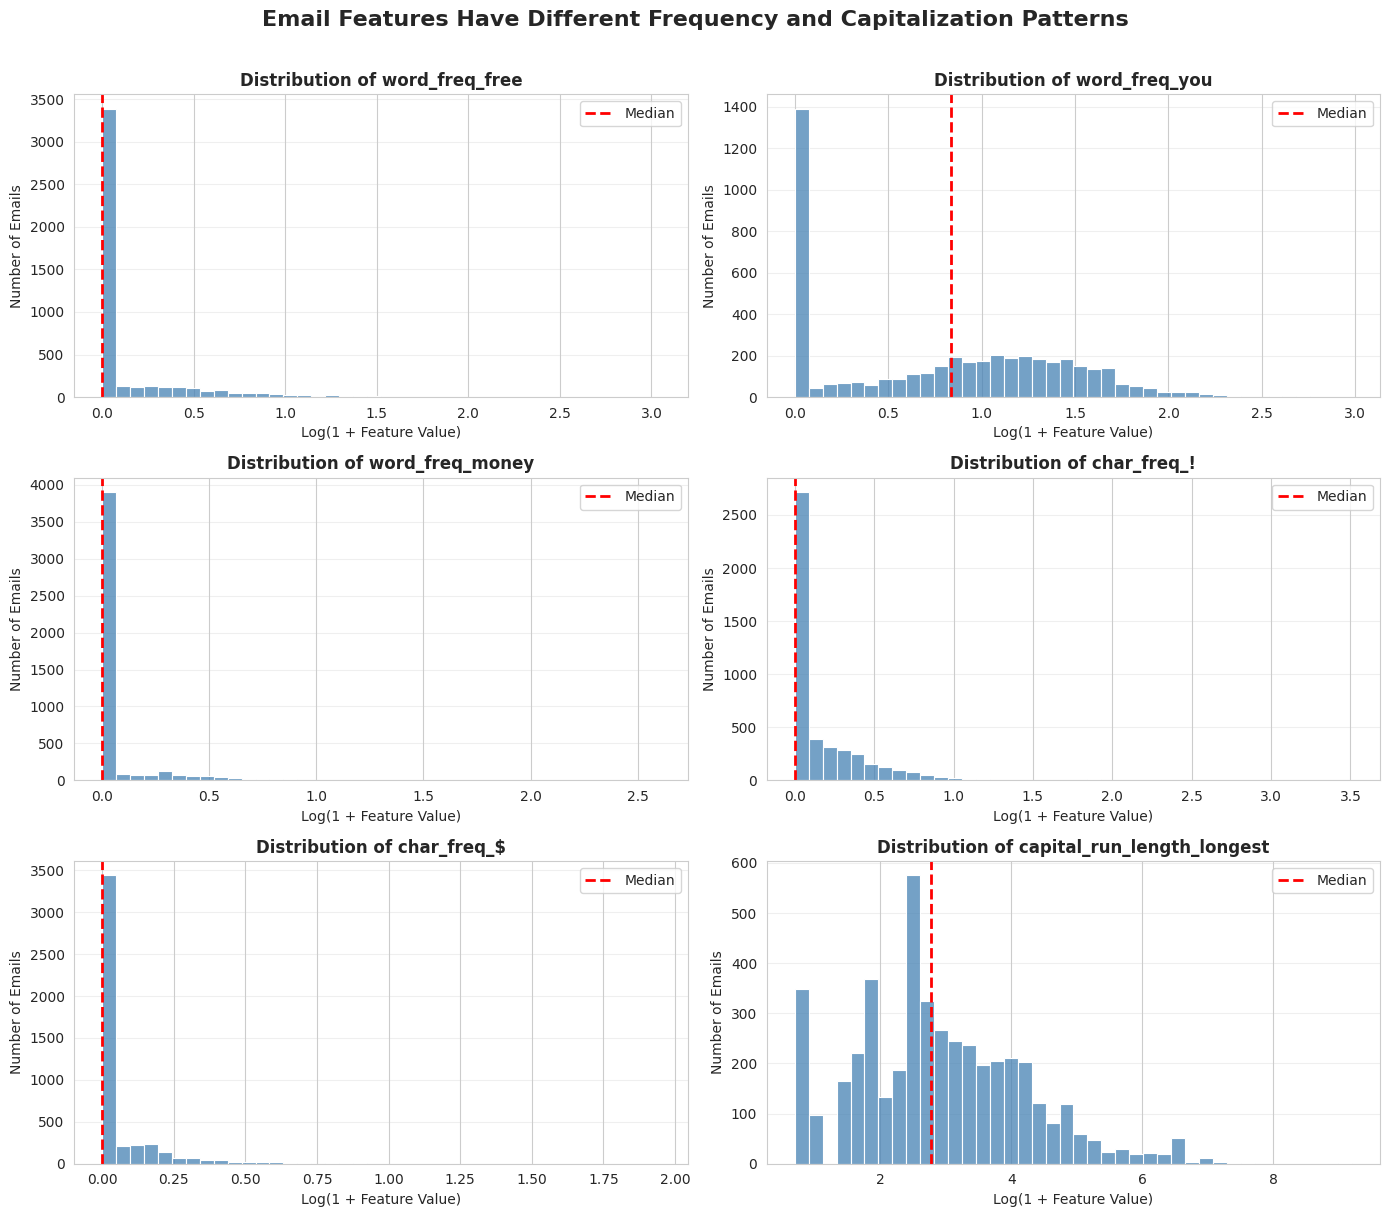

In [18]:
# Step 6: Visualizing Feature Distributions

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select representative features
selected_features = [
    "word_freq_free",
    "word_freq_you",
    "word_freq_money",
    "char_freq_!",
    "char_freq_$",
    "capital_run_length_longest"
]

# Create six histograms
fig, axes = plt.subplots(3, 2, figsize=(14, 12))

axes = axes.flatten()

for i, feature in enumerate(selected_features):

    # Use log(1+x) to make highly skewed features easier to see
    values = np.log1p(spam_df[feature])

    sns.histplot(
        values,
        bins=40,
        color="steelblue",
        edgecolor="white",
        ax=axes[i]
    )

    # Add the median as a reference line
    median_value = np.log1p(spam_df[feature].median())

    axes[i].axvline(
        median_value,
        color="red",
        linestyle="--",
        linewidth=2,
        label="Median"
    )

    # Clear, readable labels
    axes[i].set_title(
        f"Distribution of {feature}",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel("Log(1 + Feature Value)")
    axes[i].set_ylabel("Number of Emails")
    axes[i].legend()
    axes[i].grid(axis="y", alpha=0.3)

plt.suptitle(
    "Email Features Have Different Frequency and Capitalization Patterns",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

# Step 7 – Compare Word Frequencies Between Spam and Ham Emails

In Step 6, we discovered that many email features have zero values and right-skewed distributions.

However, those histograms included spam and ham emails together.

Now we want to understand whether certain words occur more frequently in spam emails than in legitimate (ham) emails.

In this step, I will compare the average frequencies of selected words between spam and ham emails.

I will use a grouped bar chart to identify differences in word usage between the two categories. This will help me understand which words may be useful for spam classification.

# Interpretation: How Word Usage Differs Between Spam and Ham

Chart shows that spam and legitimate (ham) emails use certain words at very different frequencies. This is important because these differences may help our machine learning model identify spam.

1. Understanding the Chart

- Blue bars represent legitimate (ham) emails.
- Orange bars represent spam emails.

- Longer bars mean the word appears more frequently, on average, within that email category.

- The numbers are average word frequencies expressed as percentages, not the percentage of emails containing the word.

For example, free = 0.52% for spam means that, on average, 0.52% of the words in a spam email are "free."

# Step 7 – Comparing Word Frequencies Between Spam and Ham

I compared the average frequencies of six selected words between spam and ham emails to identify differences in word usage.

The results showed that "free," "money," "you," "your," and "remove" have higher average frequencies in spam emails. For example, "free" has an average frequency of 0.52% in spam compared with 0.07% in ham. Similarly, "your" has an average frequency of 1.38% in spam compared with 0.44% in ham.

In contrast, "hp" has a higher average frequency in ham emails (0.90%) than in spam emails (0.02%).

These findings suggest that word-frequency patterns may help distinguish spam from legitimate emails. However, the differences in average frequency do not establish which features are most important for classification. I will evaluate feature importance after training the classification models.

=== AVERAGE WORD FREQUENCIES: HAM VS SPAM ===


,Ham,Spam
word_freq_free,0.074,0.518
word_freq_money,0.017,0.213
word_freq_you,1.270,2.265
word_freq_your,0.439,1.380
word_freq_remove,0.009,0.275
word_freq_hp,0.895,0.017


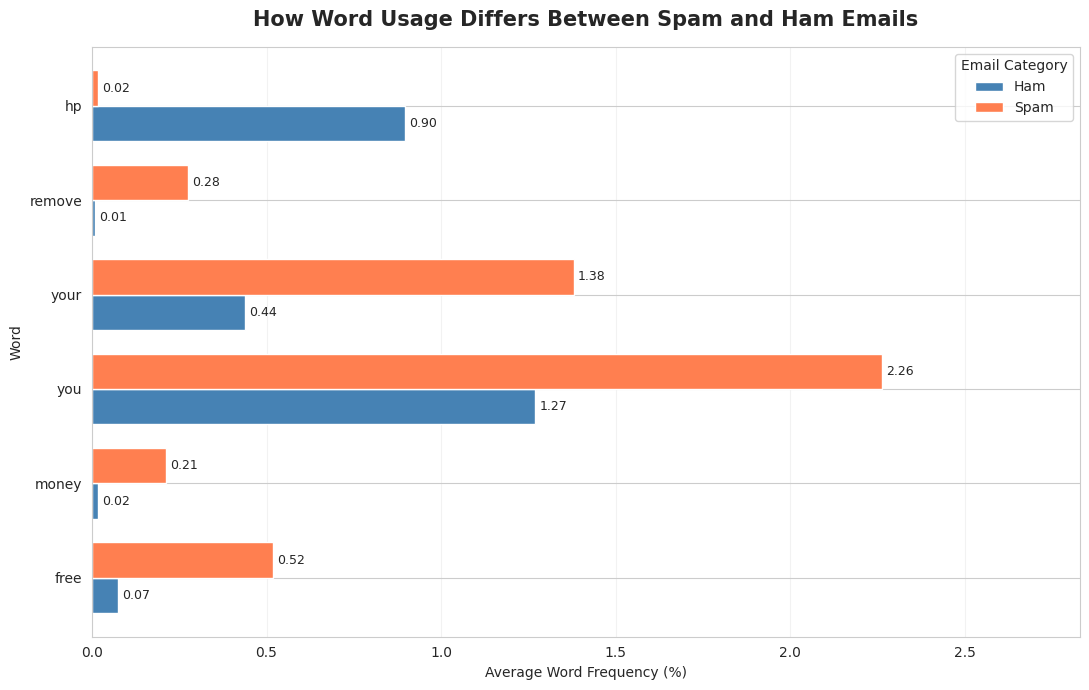

In [19]:
# Step 7: Compare Word Frequencies Between Spam and Ham

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select words to compare
selected_words = [
    "word_freq_free",
    "word_freq_money",
    "word_freq_you",
    "word_freq_your",
    "word_freq_remove",
    "word_freq_hp"
]

# Calculate average frequency for each word by email category
word_comparison = (
    spam_df.groupby("spam")[selected_words]
    .mean()
    .T
)

# Rename columns for readability
word_comparison.columns = ["Ham", "Spam"]

# Display the comparison table
print("=== AVERAGE WORD FREQUENCIES: HAM VS SPAM ===")
display(word_comparison.round(3))

# Create a grouped horizontal bar chart
ax = word_comparison.plot(
    kind="barh",
    figsize=(11, 7),
    color=["steelblue", "coral"],
    width=0.75
)

# Improve labels
ax.set_yticklabels(
    [word.replace("word_freq_", "") for word in selected_words]
)

ax.set_title(
    "How Word Usage Differs Between Spam and Ham Emails",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Average Word Frequency (%)")
ax.set_ylabel("Word")
ax.legend(title="Email Category")

# Add value labels to bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

# Leave space for annotations
ax.set_xlim(0, word_comparison.max().max() * 1.25)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Step 8 – Compare Character Frequencies and Capitalization Between Spam and Ham
In Step 7, we discovered that words such as "free," "money," and "your" have higher average frequencies in spam emails, while "hp" is more frequent in ham emails.

Now we will investigate whether special characters and capital letters also differ between spam and ham emails.

In this step, I will compare the average frequencies of six special characters and three capitalization features between spam and ham emails.

I will use two separate bar charts because character frequencies are percentages, while capitalization features measure counts or lengths.

This analysis will help me identify additional patterns that may be useful for spam classification.

What Are the Key Findings?
Finding 1: Spam emails contain more exclamation marks.

The average exclamation-mark frequency is 0.514% in spam compared with 0.110% in ham.

This may reflect promotional or attention-grabbing language.

Finding 2: Dollar signs show a particularly large difference.

Dollar signs appear about 14.5 times as frequently in spam as in ham, on average.

This suggests that financial language and symbols may be useful indicators for identifying spam in this dataset.

Finding 3: Some characters are more frequent in ham.

Semicolons, parentheses, and brackets have higher average frequencies in legitimate emails.

These characters may reflect different writing patterns, but we cannot determine their exact purpose from the numerical features alone.

### Character Frequency Comparison

I compared the average frequencies of six special characters between spam and ham emails.


The results showed that exclamation marks (`!`), dollar signs (`$`), and hash symbols (`#`) have higher average frequencies in spam emails. The dollar sign showed a particularly large difference, with an average frequency of 0.174% in spam compared with 0.012% in ham.


In contrast, semicolons (`;`), opening parentheses (`(`), and opening brackets (`[`) were more frequent in ham emails.


These findings suggest that special-character usage may help distinguish spam from legitimate emails.


I will include these features in my classification analysis and evaluate their predictive importance after training the models.

=== CHARACTER FREQUENCY COMPARISON ===


,Ham,Spam
char_freq_;,0.050,0.021
char_freq_(,0.159,0.109
char_freq_[,0.023,0.008
char_freq_!,0.110,0.514
char_freq_$,0.012,0.174
char_freq_#,0.022,0.079


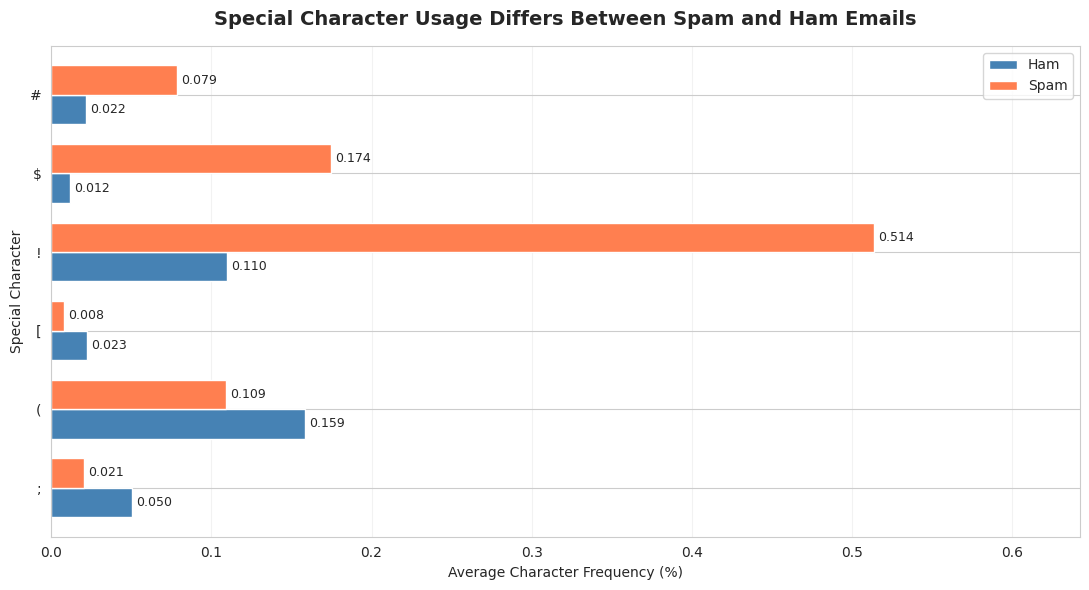


=== CAPITALIZATION COMPARISON ===


,Ham,Spam
capital_run_length_average,2.38,9.52
capital_run_length_longest,18.21,104.39
capital_run_length_total,161.47,470.62


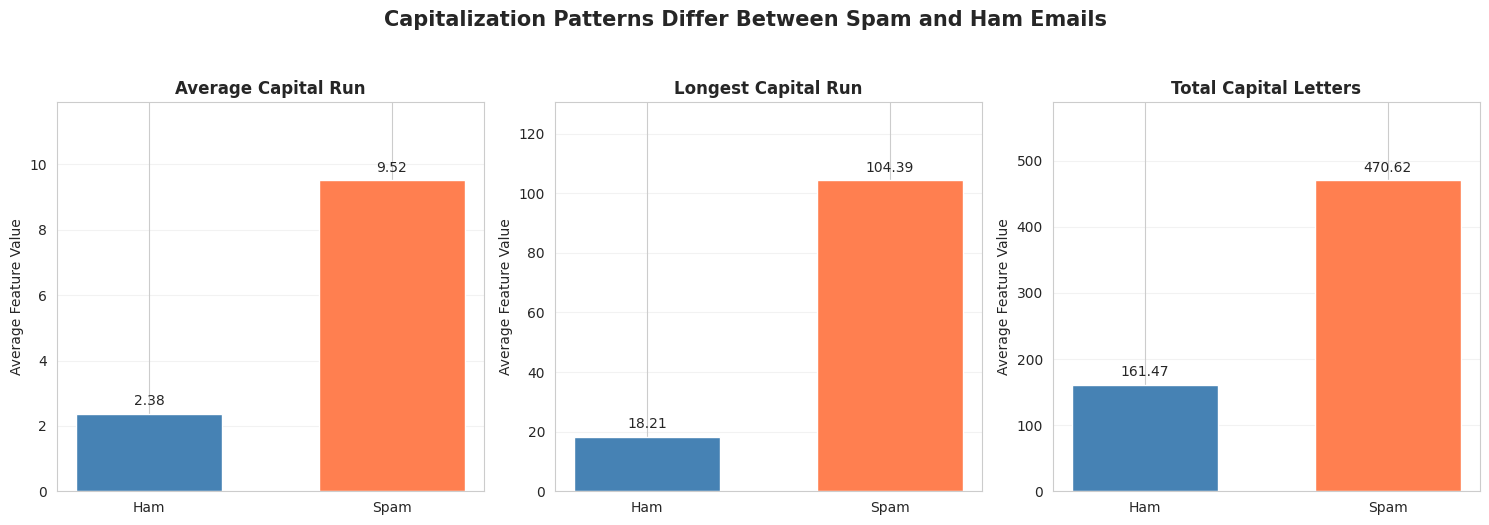

In [20]:
# Step 8: Character Frequencies and Capitalization
# Comparison Between Spam and Ham

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------
# Part A: Character Frequency Comparison
# ---------------------------------------

character_features = [
    "char_freq_;",
    "char_freq_(",
    "char_freq_[",
    "char_freq_!",
    "char_freq_$",
    "char_freq_#"
]

# Calculate average character frequencies
char_comparison = (
    spam_df.groupby("spam")[character_features]
    .mean()
    .T
)

char_comparison.columns = ["Ham", "Spam"]

print("=== CHARACTER FREQUENCY COMPARISON ===")
display(char_comparison.round(3))

# Create horizontal bar chart
ax = char_comparison.plot(
    kind="barh",
    figsize=(11, 6),
    color=["steelblue", "coral"],
    width=0.75
)

ax.set_yticklabels(
    [feature.replace("char_freq_", "") for feature in character_features]
)

ax.set_title(
    "Special Character Usage Differs Between Spam and Ham Emails",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Average Character Frequency (%)")
ax.set_ylabel("Special Character")

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

ax.set_xlim(0, char_comparison.max().max() * 1.25)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


# ---------------------------------------
# Part B: Capitalization Comparison
# ---------------------------------------

capital_features = [
    "capital_run_length_average",
    "capital_run_length_longest",
    "capital_run_length_total"
]

# Calculate average capitalization values
capital_comparison = (
    spam_df.groupby("spam")[capital_features]
    .mean()
    .T
)

capital_comparison.columns = ["Ham", "Spam"]

print("\n=== CAPITALIZATION COMPARISON ===")
display(capital_comparison.round(2))

# Create a separate chart for each capitalization feature
# because their numerical ranges differ substantially.

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

labels = [
    "Average Capital Run",
    "Longest Capital Run",
    "Total Capital Letters"
]

for i, feature in enumerate(capital_features):

    values = capital_comparison.loc[feature]

    bars = axes[i].bar(
        ["Ham", "Spam"],
        values,
        color=["steelblue", "coral"],
        width=0.6
    )

    axes[i].set_title(
        labels[i],
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_ylabel("Average Feature Value")

    axes[i].set_ylim(0, values.max() * 1.25)

    axes[i].bar_label(
        bars,
        fmt="%.2f",
        padding=4,
        fontsize=10
    )

    axes[i].grid(axis="y", alpha=0.25)
    axes[i].set_axisbelow(True)

plt.suptitle(
    "Capitalization Patterns Differ Between Spam and Ham Emails",
    fontsize=15,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()
plt.show()

# Step 8B – Comparing Capitalization Between Spam and Ham Emails

We have completed the special-character comparison. Now we will examine whether spam emails use capital letters differently from legitimate emails.

# Three Important Findings

Finding 1: Spam has longer uppercase sequences.

The median average capital run is 3.62 in spam compared with 1.86 in ham. This means a typical spam email has longer consecutive uppercase-letter sequences.

Finding 2: Extreme values increase the averages.

For the longest capital run, the spam mean is 104.39, but its median is only 38.

This large difference suggests that unusually long uppercase sequences are pulling the average upward.

Finding 3: Spam contains more capital letters overall.

The median total uppercase-letter count is 194 for spam compared with 54 for ham.

This means the middle spam email contains about 3.6 times as many uppercase letters as the middle ham email.

However, total uppercase letters can also be affected by email length.

In [21]:
# Step 8B: Capitalization Comparison

# Display average capitalization statistics
print("=== CAPITALIZATION: HAM VS SPAM ===")
display(capital_comparison.round(2))

# Display median capitalization statistics
capital_medians = (
    spam_df.groupby("spam")[capital_features]
    .median()
    .T
)

capital_medians.columns = ["Ham", "Spam"]

print("\n=== MEDIAN CAPITALIZATION: HAM VS SPAM ===")
display(capital_medians.round(2))

=== CAPITALIZATION: HAM VS SPAM ===


,Ham,Spam
capital_run_length_average,2.38,9.52
capital_run_length_longest,18.21,104.39
capital_run_length_total,161.47,470.62



=== MEDIAN CAPITALIZATION: HAM VS SPAM ===


,Ham,Spam
capital_run_length_average,1.86,3.62
capital_run_length_longest,10.00,38.00
capital_run_length_total,54.00,194.00


# Step 9 – Correlation Analysis: Understanding Relationships Between Email Features

We have completed Step 8, where we discovered that spam emails generally have higher frequencies of certain words, special characters, and capital letters.

Now we will examine how the numerical features are related to one another and to spam classification.

In this step, I will calculate correlations between the 57 numerical features and the target variable spam.

I will create a horizontal bar chart showing the 10 strongest positive and 10 strongest negative correlations with spam.

This will help me identify which features are associated with spam and which are associated with legitimate emails.

What Is Correlation?
Correlation measures the strength and direction of a relationship between two numerical variables.

It ranges from -1 to +1.

=== TOP 10 FEATURES ASSOCIATED WITH HAM ===


,Correlation
word_freq_hp,-0.257
word_freq_hpl,-0.233
word_freq_george,-0.183
word_freq_1999,-0.178
word_freq_labs,-0.171
word_freq_650,-0.159
word_freq_85,-0.149
word_freq_edu,-0.146
word_freq_re,-0.140
word_freq_meeting,-0.137



=== TOP 10 FEATURES ASSOCIATED WITH SPAM ===


,Correlation
word_freq_your,0.383
word_freq_000,0.335
word_freq_remove,0.332
char_freq_$,0.324
word_freq_you,0.274
word_freq_free,0.263
word_freq_business,0.263
capital_run_length_total,0.249
word_freq_our,0.242
char_freq_!,0.242


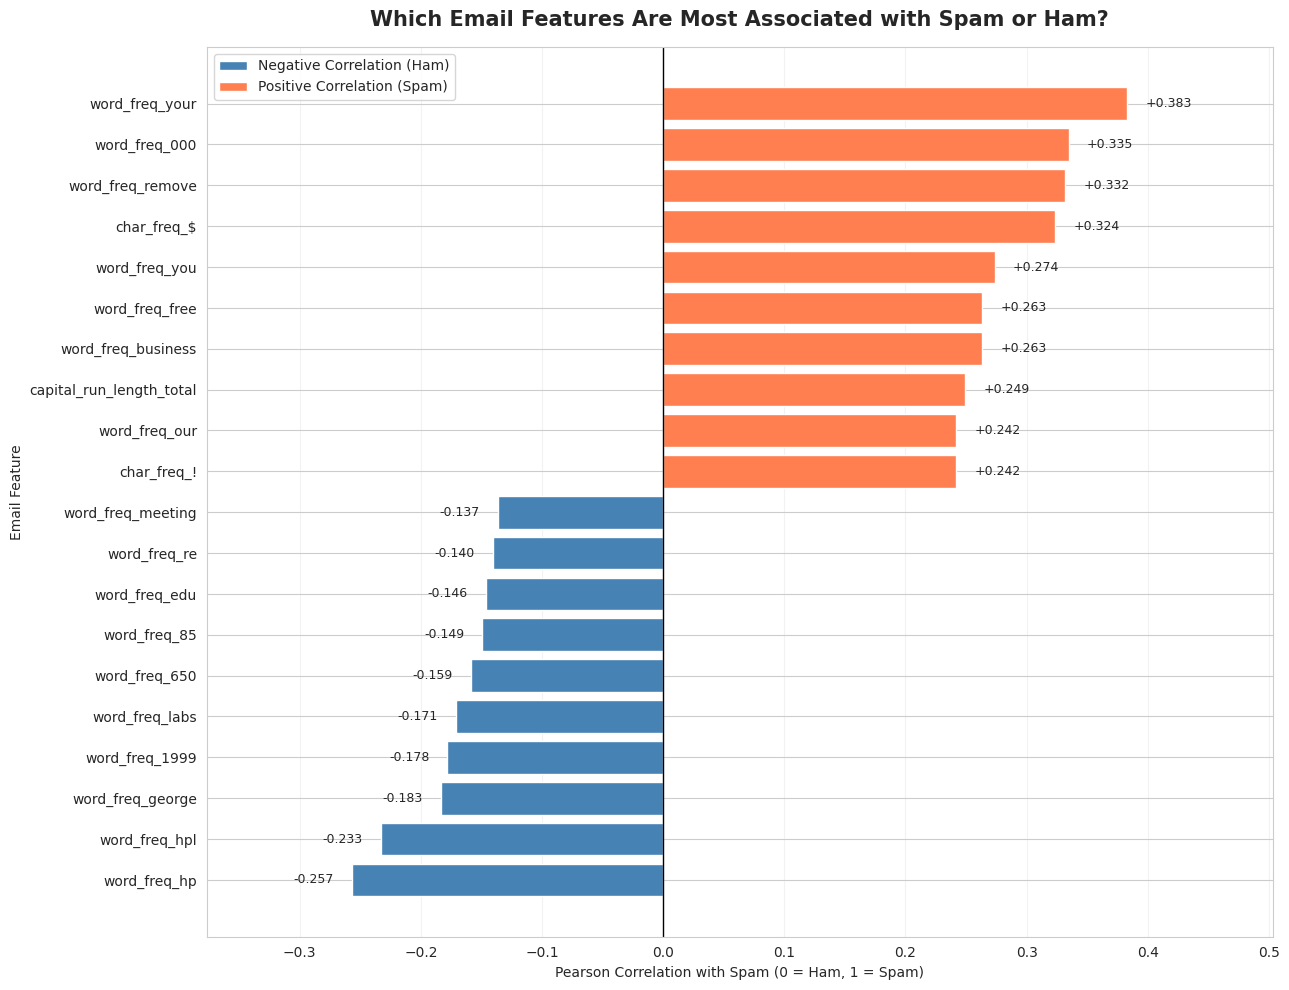

In [25]:
# Step 9: Correlation Analysis with Color Legend

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Calculate correlations
correlation_matrix = spam_df.corr(numeric_only=True)

# Extract correlations with spam target
spam_correlations = (
    correlation_matrix["spam"]
    .drop("spam")
    .sort_values()
)

# Select 10 strongest negative and positive correlations
negative_features = spam_correlations.head(10)
positive_features = spam_correlations.tail(10)

# Combine selected features
selected_correlations = pd.concat([
    negative_features,
    positive_features
]).sort_values()

# Display tables
print("=== TOP 10 FEATURES ASSOCIATED WITH HAM ===")
display(negative_features.to_frame(name="Correlation").round(3))

print("\n=== TOP 10 FEATURES ASSOCIATED WITH SPAM ===")
display(
    positive_features.sort_values(ascending=False)
    .to_frame(name="Correlation")
    .round(3)
)

# Create chart
fig, ax = plt.subplots(figsize=(13, 10))

colors = [
    "steelblue" if value < 0 else "coral"
    for value in selected_correlations
]

bars = ax.barh(
    selected_correlations.index,
    selected_correlations.values,
    color=colors
)

# Add value annotations
for bar, value in zip(bars, selected_correlations.values):

    x_position = value + 0.015 if value >= 0 else value - 0.015

    ax.text(
        x_position,
        bar.get_y() + bar.get_height() / 2,
        f"{value:+.3f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9
    )

# Add vertical reference line
ax.axvline(0, color="black", linewidth=1)

# Add color legend
legend_elements = [
    Patch(
        facecolor="steelblue",
        label="Negative Correlation (Ham)"
    ),
    Patch(
        facecolor="coral",
        label="Positive Correlation (Spam)"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper left",
    fontsize=10,
    frameon=True
)

# Titles and labels
ax.set_title(
    "Which Email Features Are Most Associated with Spam or Ham?",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Pearson Correlation with Spam (0 = Ham, 1 = Spam)"
)
ax.set_ylabel("Email Feature")

# Leave room for annotations
ax.set_xlim(
    selected_correlations.min() - 0.12,
    selected_correlations.max() + 0.12
)

ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Step 10 – Correlation Heatmap: Relationships Between Email Features

Now we will examine how the features are related to each other.

This is important because some words or email characteristics may occur together.

What Are the Key Findings?
Finding 1: "HP" and "HPL" are related.

Their correlation is +0.52, the highest visible correlation between different features in your heatmap.

This suggests that emails with higher frequencies of "hp" also tend to have higher frequencies of "hpl."

Finding 2: Capitalization features are related.

The average and longest capital runs have a correlation of +0.49, while the longest run and total capital letters have a correlation of +0.48.

This makes sense because these features describe related characteristics of uppercase text.

Finding 3: "You" and "Your" have a positive relationship.

Their correlation is +0.30. Emails that frequently contain "you" may also tend to contain "your," although the relationship is not particularly strong.

Finding 4: Most other correlations are weak.

Many cells are white or very pale, with coefficients close to zero.

This indicates that most selected features do not have strong linear relationships with each other.
4. Does This Mean We Have Multicollinearity?
Multicollinearity occurs when predictors are strongly linearly related, potentially making model coefficients difficult to interpret.

Heatmap shows some moderate correlations, but none of the displayed feature pairs have correlations above 0.70 in absolute value.

Therefore, this selected set does not show obvious severe pairwise multicollinearity.

=== FEATURE CORRELATION MATRIX ===


,word_freq_free,word_freq_money,word_freq_you,word_freq_your,word_freq_remove,word_freq_business,word_freq_hp,word_freq_hpl,word_freq_george,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total
word_freq_free,1.00,0.10,0.08,0.10,0.13,0.06,-0.09,-0.08,-0.00,0.10,0.05,0.04,0.02,0.03,0.00
word_freq_money,0.10,1.00,0.18,0.17,0.03,0.04,-0.07,-0.06,-0.05,0.05,0.10,0.00,0.01,0.04,0.08
word_freq_you,0.08,0.18,1.00,0.30,0.11,0.08,-0.20,-0.16,-0.15,0.15,0.09,-0.00,-0.03,0.01,-0.01
word_freq_your,0.10,0.17,0.30,1.00,0.13,0.22,-0.15,-0.14,-0.13,0.08,0.14,-0.00,0.04,0.09,0.05
word_freq_remove,0.13,0.03,0.11,0.13,1.00,0.19,-0.09,-0.08,-0.07,0.05,0.07,0.05,0.04,0.06,-0.01
word_freq_business,0.06,0.04,0.08,0.22,0.19,1.00,-0.05,-0.08,-0.07,0.08,0.10,-0.00,0.04,0.06,0.06
word_freq_hp,-0.09,-0.07,-0.20,-0.15,-0.09,-0.05,1.00,0.52,-0.01,-0.09,-0.09,0.06,-0.02,-0.05,-0.04
word_freq_hpl,-0.08,-0.06,-0.16,-0.14,-0.08,-0.08,0.52,1.00,0.01,-0.08,-0.08,-0.02,-0.02,-0.05,-0.06
word_freq_george,-0.00,-0.05,-0.15,-0.13,-0.07,-0.07,-0.01,0.01,1.00,-0.07,-0.07,-0.02,-0.03,-0.05,-0.10
char_freq_!,0.10,0.05,0.15,0.08,0.05,0.08,-0.09,-0.08,-0.07,1.00,0.14,0.02,0.05,0.08,0.04


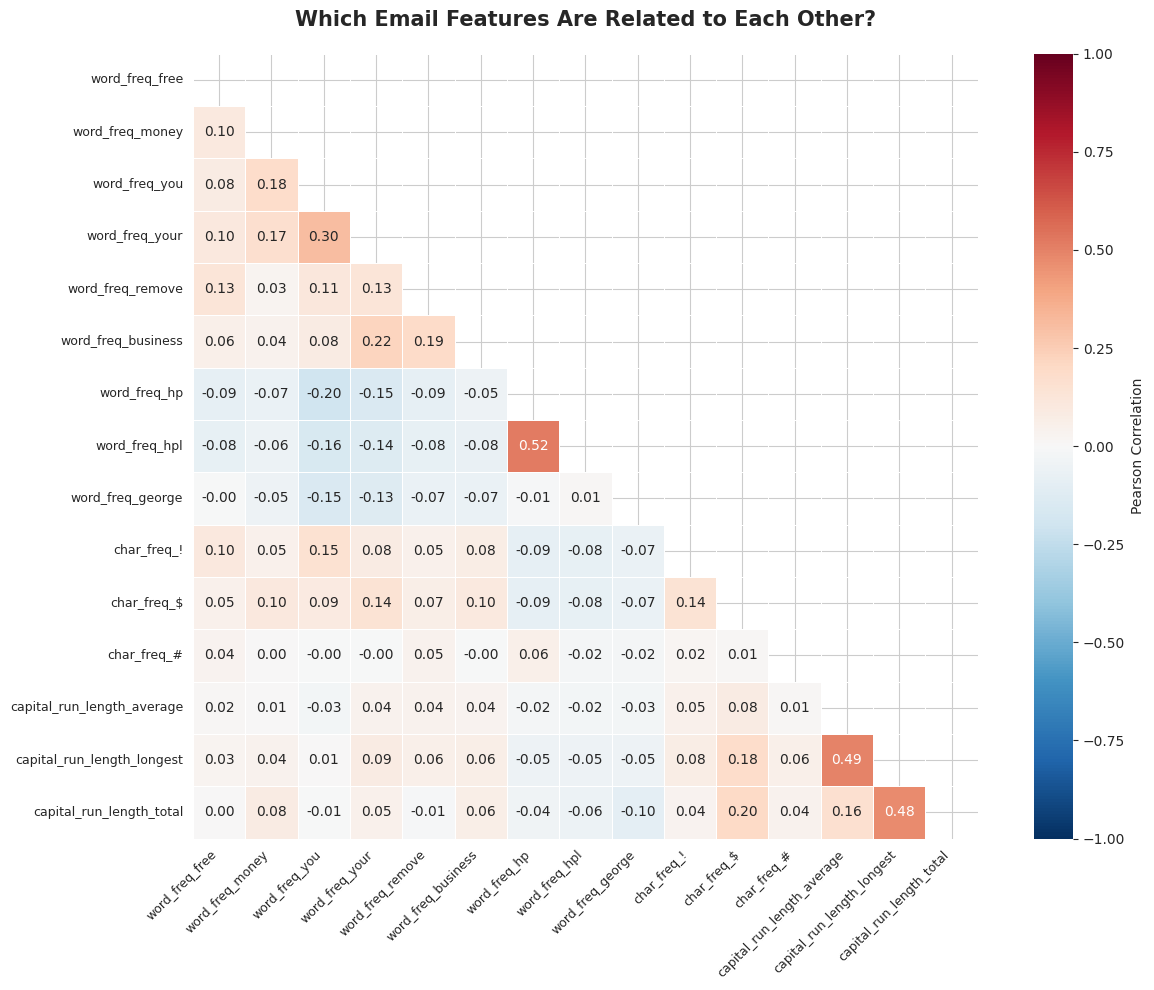

In [26]:
# Step 10: Correlation Heatmap Between Email Features

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select representative features from different groups
selected_features = [
    "word_freq_free",
    "word_freq_money",
    "word_freq_you",
    "word_freq_your",
    "word_freq_remove",
    "word_freq_business",
    "word_freq_hp",
    "word_freq_hpl",
    "word_freq_george",
    "char_freq_!",
    "char_freq_$",
    "char_freq_#",
    "capital_run_length_average",
    "capital_run_length_longest",
    "capital_run_length_total"
]

# Calculate correlations between selected features
feature_corr = spam_df[selected_features].corr()

# Display the correlation matrix
print("=== FEATURE CORRELATION MATRIX ===")
display(feature_corr.round(2))

# Create a mask to hide the upper triangle
mask = np.triu(np.ones_like(feature_corr, dtype=bool))

# Create heatmap
plt.figure(figsize=(13, 10))

sns.heatmap(
    feature_corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title(
    "Which Email Features Are Related to Each Other?",
    fontsize=15,
    fontweight="bold",
    pad=20
)

plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

# Step 11 – Data Preprocessing: Handling Duplicate Records

We have completed our exploratory data analysis (EDA), including descriptive statistics, histograms, spam-versus-ham comparisons, and correlation analysis.

Now we are ready to prepare the dataset for machine learning.

Before splitting the dataset into training and testing sets, we need to address duplicate records.

In this step, I will examine duplicate observations in the Spambase dataset and prepare a cleaned dataset for classification.

Earlier, I discovered that the dataset contains 391 exact duplicate rows and three feature patterns with conflicting spam labels.

I will remove exact duplicate rows while retaining the original dataset for reference. I will also identify conflicting feature patterns rather than arbitrarily changing their labels.

In [27]:
# Step 11: Prepare Dataset and Examine Duplicates

# Keep the original dataset unchanged
spam_original_df = spam_df.copy()

# Count exact duplicate rows
exact_duplicates = spam_df.duplicated().sum()

print("=== DUPLICATE SUMMARY ===")
print("Original observations:", len(spam_df))
print("Exact duplicate rows:", exact_duplicates)

# Remove exact duplicate rows
spam_clean_df = spam_df.drop_duplicates().copy()

print("Observations after removing exact duplicates:",
      len(spam_clean_df))

# Identify feature columns
feature_columns = spam_clean_df.columns.drop("spam").tolist()

# Count how many distinct labels exist for each feature pattern
label_counts = (
    spam_clean_df
    .groupby(feature_columns)["spam"]
    .nunique()
)

# Identify conflicting feature patterns
conflicting_patterns = (label_counts > 1).sum()

print("\n=== CONFLICTING FEATURE PATTERNS ===")
print("Number of conflicting patterns:", conflicting_patterns)

# Confirm that the cleaned dataset has no exact duplicates
print("\nRemaining exact duplicates:",
      spam_clean_df.duplicated().sum())

# Display cleaned dataset dimensions
print("\nCleaned dataset shape:", spam_clean_df.shape)

=== DUPLICATE SUMMARY ===
Original observations: 4601
Exact duplicate rows: 391
Observations after removing exact duplicates: 4210

=== CONFLICTING FEATURE PATTERNS ===
Number of conflicting patterns: 3

Remaining exact duplicates: 0

Cleaned dataset shape: (4210, 58)


# Step 12 – Preparing Training and Testing Datasets for Spam Classification

We have completed Step 11, where we prepared the cleaned Spambase dataset by removing exact duplicate rows.

Now we will divide the data into training and testing datasets so we can build and evaluate our classification models.

In this step, I will separate the 57 numerical predictors from the target variable spam.

I will then divide the cleaned dataset into 80% training data and 20% testing data.

I will also make sure that emails with identical numerical feature patterns stay in the same dataset to prevent data leakage.

In [28]:
# Step 12: Separate Features and Target
# Create Training and Testing Datasets

import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

# ---------------------------------------
# Part A: Separate predictors and target
# ---------------------------------------

# X contains the 57 numerical email features
X = spam_clean_df.drop(columns=["spam"])

# y contains the target:
# 0 = Ham, 1 = Spam
y = spam_clean_df["spam"]

print("=== FEATURES AND TARGET ===")
print("X shape:", X.shape)
print("y shape:", y.shape)

# ---------------------------------------
# Part B: Identify identical feature patterns
# ---------------------------------------

# Give identical feature patterns the same group ID
groups = pd.factorize(
    pd.MultiIndex.from_frame(X)
)[0]

print("\nUnique feature patterns:", len(set(groups)))

# ---------------------------------------
# Part C: Create an 80/20 group-aware split
# ---------------------------------------

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Create training and testing datasets
X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# ---------------------------------------
# Part D: Check dataset sizes
# ---------------------------------------

print("\n=== TRAINING AND TESTING DATA ===")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# ---------------------------------------
# Part E: Check spam and ham proportions
# ---------------------------------------

print("\n=== TRAINING CLASS DISTRIBUTION (%) ===")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\n=== TESTING CLASS DISTRIBUTION (%) ===")
print((y_test.value_counts(normalize=True) * 100).round(2))

# ---------------------------------------
# Part F: Verify no group leakage
# ---------------------------------------

train_groups = set(groups[train_idx])
test_groups = set(groups[test_idx])

overlap = train_groups.intersection(test_groups)

print("\n=== DATA LEAKAGE CHECK ===")
print("Shared feature patterns:", len(overlap))

assert len(overlap) == 0, "Data leakage detected!"

print("Group leakage check passed.")

=== FEATURES AND TARGET ===
X shape: (4210, 57)
y shape: (4210,)

Unique feature patterns: 4207

=== TRAINING AND TESTING DATA ===
X_train: (3367, 57)
X_test: (843, 57)
y_train: (3367,)
y_test: (843,)

=== TRAINING CLASS DISTRIBUTION (%) ===
spam
0    60.94
1    39.06
Name: proportion, dtype: float64

=== TESTING CLASS DISTRIBUTION (%) ===
spam
0    56.82
1    43.18
Name: proportion, dtype: float64

=== DATA LEAKAGE CHECK ===
Shared feature patterns: 0
Group leakage check passed.


# Step 13 – Build a Baseline Spam Classification Model

We have completed the data preparation stage. Now we are ready to begin machine learning.

Before training Logistic Regression, Naive Bayes, or Decision Trees, we should create a baseline model.

A baseline gives us a simple result that we can use to evaluate whether our more advanced models are actually performing better.

In this step, I will build a baseline classification model using DummyClassifier from scikit-learn.

The model will always predict the most common email category in the training dataset, either spam or ham.

I will evaluate its predictions using accuracy, precision, recall, F1-score, and a confusion matrix.

What Is a Baseline Model?

Imagine our training dataset contains:
Email Category	Percentage
Ham	60%
Spam	40%

A baseline model that always predicts ham would achieve approximately 60% accuracy on a test dataset with the same class proportions.

However, it would fail to identify any spam emails.

This is why accuracy alone is not enough for spam classification.

# Interpretation – Baseline Classification Model

I developed a baseline classification model using DummyClassifier with the most-frequent-class strategy.

The model achieved an accuracy of 56.8%. However, the confusion matrix showed that it classified all 843 test emails as ham.

Although the model correctly identified all 479 legitimate emails, it failed to detect any of the 364 spam emails. As a result, spam precision, recall, and F1-score were all zero.

These results demonstrate that accuracy alone is not sufficient for evaluating spam classification. I will use this baseline to compare more advanced machine learning models, focusing on improving spam detection while minimizing false positives.

=== BASELINE MODEL PERFORMANCE ===


,Metric,Baseline Score
0,Accuracy,0.568
1,Precision,0.000
2,Recall,0.000
3,F1-Score,0.000



=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

         Ham       0.57      1.00      0.72       479
        Spam       0.00      0.00      0.00       364

    accuracy                           0.57       843
   macro avg       0.28      0.50      0.36       843
weighted avg       0.32      0.57      0.41       843



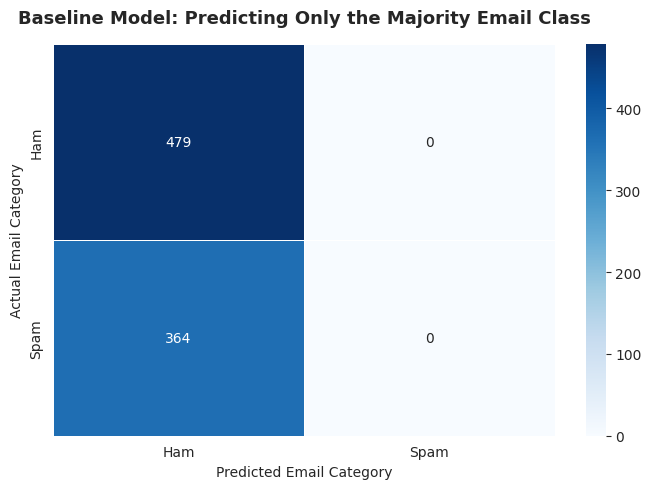


=== BASELINE PREDICTIONS ===
Ham    843
Name: count, dtype: int64


In [29]:
# Step 13: Baseline Spam Classification Model

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ---------------------------------------
# Part A: Create the baseline model
# ---------------------------------------

baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train the model using training data only
baseline_model.fit(X_train, y_train)

# Predict email categories on test data
baseline_predictions = baseline_model.predict(X_test)

# ---------------------------------------
# Part B: Calculate evaluation metrics
# ---------------------------------------

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

baseline_precision = precision_score(
    y_test, baseline_predictions,
    zero_division=0
)

baseline_recall = recall_score(
    y_test, baseline_predictions,
    zero_division=0
)

baseline_f1 = f1_score(
    y_test, baseline_predictions,
    zero_division=0
)

# Display results
baseline_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Baseline Score": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1
    ]
})

print("=== BASELINE MODEL PERFORMANCE ===")
display(baseline_results.round(3))

print("\n=== CLASSIFICATION REPORT ===")
print(
    classification_report(
        y_test,
        baseline_predictions,
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

# ---------------------------------------
# Part C: Confusion Matrix
# ---------------------------------------

cm = confusion_matrix(
    y_test,
    baseline_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"],
    linewidths=0.5
)

plt.title(
    "Baseline Model: Predicting Only the Majority Email Class",
    fontsize=13,
    fontweight="bold",
    pad=15
)

plt.xlabel("Predicted Email Category")
plt.ylabel("Actual Email Category")

plt.tight_layout()
plt.show()

# ---------------------------------------
# Part D: Check model predictions
# ---------------------------------------

print("\n=== BASELINE PREDICTIONS ===")
print(
    pd.Series(baseline_predictions)
    .map({0: "Ham", 1: "Spam"})
    .value_counts()
)

# Step 14 – Training a Logistic Regression Model for Spam Classification
We have completed Step 13, where our baseline model achieved 56.8% accuracy but detected 0% of spam emails.

Now we will train our first real machine learning model: Logistic Regression.

Our goal is to improve spam detection using the 57 numerical features in the Spambase dataset.

In this step, I will train a Logistic Regression model to classify emails as Spam (1) or Ham (0).

I will standardize the numerical features using StandardScaler, train the model using the training dataset, and evaluate its performance on the testing dataset.

I will compare the Logistic Regression results with the baseline model using accuracy, precision, recall, and F1-score.
2. What Is Logistic Regression?
Logistic Regression is a supervised machine learning algorithm used for classification.

Despite its name, it predicts the probability that an observation belongs to a particular category.

For our Spambase dataset:
- 0 = Ham: Legitimate email
- 1 = Spam: Unwanted email

### Step 14 – Logistic Regression Classification

I selected Logistic Regression as my first supervised classification model because it is suitable for binary classification and provides interpretable model coefficients.

I used the 57 numerical features in the Spambase dataset to predict whether an email was spam or ham.

Before training, I applied StandardScaler through a scikit-learn Pipeline to standardize the predictors. The scaling parameters were learned only from the training dataset to prevent data leakage.

I trained the Logistic Regression model using the training data and evaluated its predictions using the testing data.

I will compare the model's accuracy, precision, recall, F1-score, and confusion matrix against the baseline classifier to determine whether Logistic Regression improves spam detection.

=== MODEL PERFORMANCE COMPARISON ===


,Metric,Baseline,Logistic Regression
0,Accuracy,0.568,0.913
1,Precision (Spam),0.000,0.927
2,Recall (Spam),0.000,0.868
3,F1-Score (Spam),0.000,0.896



=== LOGISTIC REGRESSION REPORT ===
              precision    recall  f1-score   support

         Ham       0.90      0.95      0.93       479
        Spam       0.93      0.87      0.90       364

    accuracy                           0.91       843
   macro avg       0.92      0.91      0.91       843
weighted avg       0.91      0.91      0.91       843



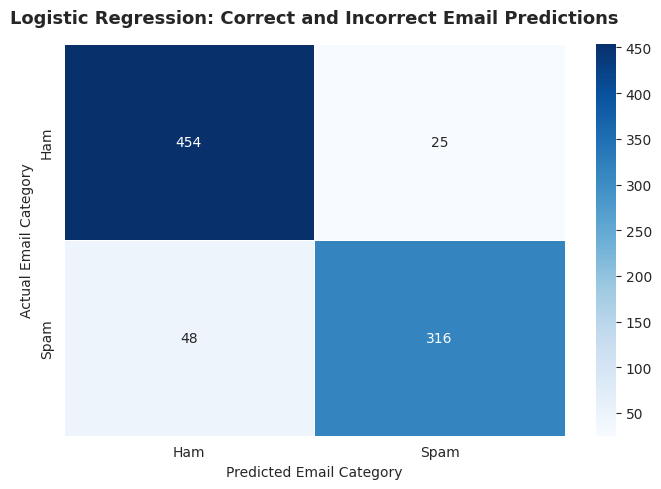

In [30]:
# Step 14: Train and Evaluate Logistic Regression

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ---------------------------------------
# Part A: Create Logistic Regression Pipeline
# ---------------------------------------

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# ---------------------------------------
# Part B: Train the model
# ---------------------------------------

logistic_model.fit(X_train, y_train)

# ---------------------------------------
# Part C: Make predictions
# ---------------------------------------

logistic_predictions = logistic_model.predict(X_test)

# ---------------------------------------
# Part D: Calculate performance metrics
# ---------------------------------------

logistic_accuracy = accuracy_score(
    y_test, logistic_predictions
)

logistic_precision = precision_score(
    y_test, logistic_predictions,
    zero_division=0
)

logistic_recall = recall_score(
    y_test, logistic_predictions,
    zero_division=0
)

logistic_f1 = f1_score(
    y_test, logistic_predictions,
    zero_division=0
)

# ---------------------------------------
# Part E: Compare with baseline model
# ---------------------------------------

comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision (Spam)",
        "Recall (Spam)",
        "F1-Score (Spam)"
    ],
    "Baseline": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1
    ],
    "Logistic Regression": [
        logistic_accuracy,
        logistic_precision,
        logistic_recall,
        logistic_f1
    ]
})

print("=== MODEL PERFORMANCE COMPARISON ===")
display(comparison_df.round(3))

# ---------------------------------------
# Part F: Classification Report
# ---------------------------------------

print("\n=== LOGISTIC REGRESSION REPORT ===")

print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

# ---------------------------------------
# Part G: Confusion Matrix
# ---------------------------------------

cm_logistic = confusion_matrix(
    y_test,
    logistic_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"],
    linewidths=0.5
)

plt.title(
    "Logistic Regression: Correct and Incorrect Email Predictions",
    fontsize=13,
    fontweight="bold",
    pad=15
)

plt.xlabel("Predicted Email Category")
plt.ylabel("Actual Email Category")

plt.tight_layout()
plt.show()

# Interpretation of Logistic Regression Results

Logistic Regression model shows a significant improvement over the baseline model. It correctly classified 91.3% of test emails and successfully detected 316 out of 364 spam emails.


I trained a Logistic Regression classification model using the 57 numerical features in the Spambase dataset. I standardized the features using StandardScaler within a machine learning pipeline.

The Logistic Regression model achieved 91.3% accuracy, 92.7% precision, 86.8% recall, and an F1-score of 89.6% for spam classification.

The confusion matrix showed that the model correctly classified 454 legitimate emails and 316 spam emails. However, 25 legitimate emails were incorrectly classified as spam, while 48 spam emails were incorrectly classified as legitimate.

Compared with the baseline model, which achieved 56.8% accuracy and failed to detect any spam emails, Logistic Regression demonstrated a substantial improvement.

These results indicate that Logistic Regression is effective at identifying spam using numerical word frequencies, character frequencies, and capitalization patterns.

Although the model performs well, further improvements may be possible by examining feature importance and evaluating alternative classification algorithms.

# Step 15 – Logistic Regression Feature Importance Analysis

Now we want to answer an important question:

Which email features help the Logistic Regression model distinguish Spam from Ham?

This step is particularly important because we are looking at feature importance

In this step, I will examine the coefficients of my trained Logistic Regression model to identify which email features are most strongly associated with Spam and Ham predictions.

I will use the standardized coefficients to compare the relative influence of the 57 numerical features.

I will then create a horizontal bar chart showing the top 10 positive and top 10 negative coefficients


What Is Feature Importance in Logistic Regression?
Logistic Regression assigns a coefficient to each predictor.

The coefficient indicates how the predictor is associated with the model's predicted probability of Spam, while holding other features constant.

# Interpretation of Logistic Regression Feature Importance

feature importance results show that Logistic Regression uses both promotional language and technical or workplace-related vocabulary to distinguish Spam from Ham.

The chart also reveals something interesting: some of the strongest coefficients are associated with legitimate emails rather than spam.

### Step 15 – Logistic Regression Feature Importance Results

I examined the standardized coefficients of my Logistic Regression model to identify the features most strongly associated with spam and legitimate emails.

The strongest positive coefficients included `char_freq_$` (1.427), `word_freq_3d` (1.187), `capital_run_length_longest` (1.161), `word_freq_remove` (0.931), and `char_freq_#` (0.889). These findings suggest that monetary symbols, promotional language, and capitalization patterns are useful indicators of spam.

The strongest negative coefficients included `word_freq_george` (-3.739), `word_freq_hp` (-2.647), `word_freq_cs` (-1.535), `word_freq_meeting` (-1.496), and `word_freq_project` (-1.361). These features were associated with legitimate emails in the dataset.

Overall, the feature importance analysis demonstrates that Logistic Regression uses both word-frequency patterns and email formatting characteristics to distinguish spam from ham.

However, these coefficients describe statistical associations within the trained model rather than causal relationships. Their interpretation may also be affected by correlations among predictors and characteristics of the original dataset.

=== TOP 20 LOGISTIC REGRESSION FEATURES ===


,Feature,Coefficient,Absolute Importance
0,word_freq_george,-3.739,3.739
1,word_freq_hp,-2.647,2.647
2,word_freq_cs,-1.535,1.535
3,word_freq_meeting,-1.496,1.496
4,char_freq_$,1.427,1.427
5,word_freq_project,-1.361,1.361
6,word_freq_lab,-1.259,1.259
7,word_freq_edu,-1.245,1.245
8,word_freq_3d,1.187,1.187
9,capital_run_length_longest,1.161,1.161


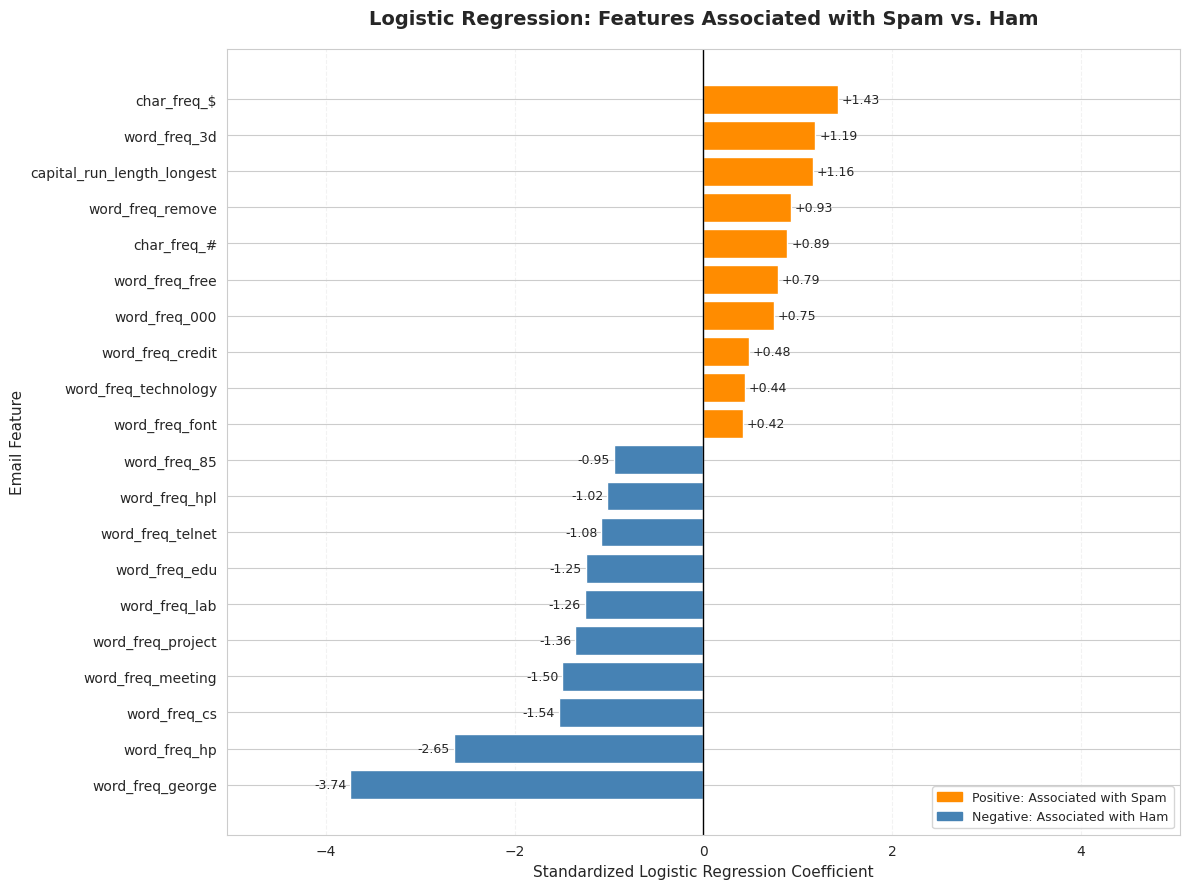

In [32]:
# Step 15: Logistic Regression Feature Importance

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------
# Part A: Extract trained model coefficients
# ---------------------------------------

# Access Logistic Regression from the pipeline
trained_logistic = logistic_model.named_steps["classifier"]

# Get the coefficient for each feature
coefficients = trained_logistic.coef_[0]

# Get the 57 feature names
feature_names = X_train.columns

# ---------------------------------------
# Part B: Create feature importance table
# ---------------------------------------

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Calculate absolute coefficient values
feature_importance_df["Absolute Importance"] = (
    feature_importance_df["Coefficient"].abs()
)

# Sort from highest to lowest absolute importance
feature_importance_df = (
    feature_importance_df
    .sort_values("Absolute Importance", ascending=False)
    .reset_index(drop=True)
)

print("=== TOP 20 LOGISTIC REGRESSION FEATURES ===")

display(
    feature_importance_df.head(20).round(3)
)

# ---------------------------------------
# Part C: Select positive and negative features
# ---------------------------------------

# Top 10 features associated with Spam
top_spam = (
    feature_importance_df[
        feature_importance_df["Coefficient"] > 0
    ]
    .nlargest(10, "Coefficient")
)

# Top 10 features associated with Ham
top_ham = (
    feature_importance_df[
        feature_importance_df["Coefficient"] < 0
    ]
    .nsmallest(10, "Coefficient")
)

# Combine and sort for visualization
top_features = pd.concat([top_spam, top_ham])

top_features = top_features.sort_values("Coefficient")

# ---------------------------------------
# Part D: Visualize feature importance
# ---------------------------------------

colors = [
    "steelblue" if value < 0 else "darkorange"
    for value in top_features["Coefficient"]
]

plt.figure(figsize=(12, 9))

bars = plt.barh(
    top_features["Feature"],
    top_features["Coefficient"],
    color=colors
)

# Vertical reference line at zero
plt.axvline(
    x=0,
    color="black",
    linewidth=1
)

# Add coefficient labels
for bar, value in zip(
    bars,
    top_features["Coefficient"]
):
    x_position = value + 0.04 if value >= 0 else value - 0.04

    plt.text(
        x_position,
        bar.get_y() + bar.get_height() / 2,
        f"{value:+.2f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9
    )

# Add space for annotations
max_abs = top_features["Coefficient"].abs().max()

plt.xlim(
    -max_abs * 1.35,
    max_abs * 1.35
)

plt.title(
    "Logistic Regression: Features Associated with Spam vs. Ham",
    fontsize=14,
    fontweight="bold",
    pad=18
)

plt.xlabel(
    "Standardized Logistic Regression Coefficient",
    fontsize=11
)

plt.ylabel("Email Feature", fontsize=11)

# Legend
from matplotlib.patches import Patch

legend_items = [
    Patch(color="darkorange", label="Positive: Associated with Spam"),
    Patch(color="steelblue", label="Negative: Associated with Ham")
]

plt.legend(
    handles=legend_items,
    loc="lower right",
    fontsize=9
)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()
plt.show()

# Step 16 – Training a Naive Bayes Classifier for Spam Detection

Now we will train a second machine learning model: Naive Bayes.

Our goal is to determine whether Naive Bayes can identify spam emails as effectively as Logistic Regression.

In this step, I will train a Gaussian Naive Bayes classifier using the 57 numerical features in the Spambase dataset.

I will use the same training and testing datasets from Step 12 to ensure a fair comparison.

I will evaluate the model using accuracy, precision, recall, F1-score, and a confusion matrix. Finally, I will compare its performance with the baseline and Logistic Regression models.

What Is Naive Bayes?
Naive Bayes is a supervised classification algorithm based on probability.

It predicts whether an email is Spam or Ham by examining its features and estimating which category is more likely.

# Interpretation of Naive Bayes Classification Results

Gaussian Naive Bayes model achieved 84.3% accuracy and 96.4% spam recall.

This reveals an important finding: Naive Bayes detects more spam emails than Logistic Regression, but it also incorrectly flags more legitimate emails as spam.

=== MODEL PERFORMANCE COMPARISON ===


,Metric,Baseline,Logistic Regression,Naive Bayes
0,Accuracy,0.568,0.913,0.843
1,Precision (Spam),0.000,0.927,0.747
2,Recall (Spam),0.000,0.868,0.964
3,F1-Score (Spam),0.000,0.896,0.842



=== NAIVE BAYES CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

         Ham       0.97      0.75      0.85       479
        Spam       0.75      0.96      0.84       364

    accuracy                           0.84       843
   macro avg       0.86      0.86      0.84       843
weighted avg       0.87      0.84      0.84       843



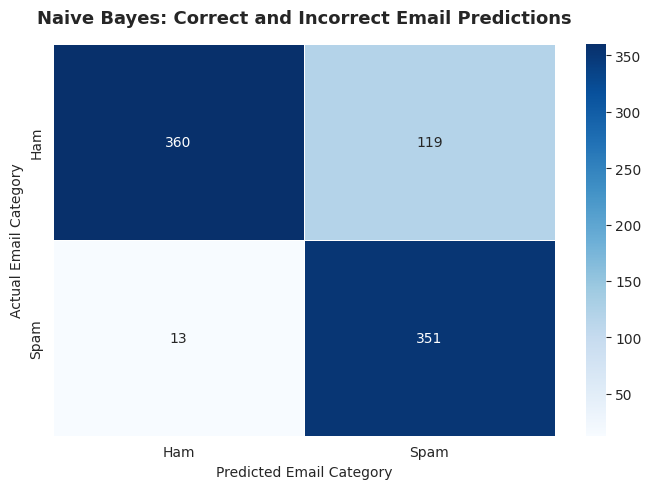

In [33]:
# Step 16: Train and Evaluate Gaussian Naive Bayes

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ---------------------------------------
# Part A: Create Naive Bayes Model
# ---------------------------------------

nb_model = GaussianNB()

# ---------------------------------------
# Part B: Train the Model
# ---------------------------------------

nb_model.fit(X_train, y_train)

# ---------------------------------------
# Part C: Make Predictions
# ---------------------------------------

nb_predictions = nb_model.predict(X_test)

# ---------------------------------------
# Part D: Calculate Evaluation Metrics
# ---------------------------------------

nb_accuracy = accuracy_score(
    y_test, nb_predictions
)

nb_precision = precision_score(
    y_test, nb_predictions,
    zero_division=0
)

nb_recall = recall_score(
    y_test, nb_predictions,
    zero_division=0
)

nb_f1 = f1_score(
    y_test, nb_predictions,
    zero_division=0
)

# ---------------------------------------
# Part E: Compare All Three Models
# ---------------------------------------

model_comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision (Spam)",
        "Recall (Spam)",
        "F1-Score (Spam)"
    ],

    "Baseline": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1
    ],

    "Logistic Regression": [
        logistic_accuracy,
        logistic_precision,
        logistic_recall,
        logistic_f1
    ],

    "Naive Bayes": [
        nb_accuracy,
        nb_precision,
        nb_recall,
        nb_f1
    ]
})

print("=== MODEL PERFORMANCE COMPARISON ===")

display(
    model_comparison_df.round(3)
)

# ---------------------------------------
# Part F: Classification Report
# ---------------------------------------

print("\n=== NAIVE BAYES CLASSIFICATION REPORT ===")

print(
    classification_report(
        y_test,
        nb_predictions,
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

# ---------------------------------------
# Part G: Confusion Matrix
# ---------------------------------------

cm_nb = confusion_matrix(
    y_test,
    nb_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"],
    linewidths=0.5
)

plt.title(
    "Naive Bayes: Correct and Incorrect Email Predictions",
    fontsize=13,
    fontweight="bold",
    pad=15
)

plt.xlabel("Predicted Email Category")
plt.ylabel("Actual Email Category")

plt.tight_layout()
plt.show()

# Step 17 – Training a Decision Tree Classifier for Spam Detection

We have trained and evaluated three models:
- Baseline Classifier
- Logistic Regression
- Gaussian Naive Bayes
Now we will train our fourth model: Decision Tree Classifier.

Our goal is to determine whether a Decision Tree can improve spam classification by identifying patterns and relationships among the 57 numerical features.

In this step, I will train a Decision Tree classifier using the same training and testing datasets from Step 12.

I will evaluate its performance using accuracy, precision, recall, F1-score, and a confusion matrix.

I will compare the Decision Tree results with the baseline, Logistic Regression, and Naive Bayes models.

I will also limit the complexity of the tree to reduce overfitting.

What Is a Decision Tree?
A Decision Tree is a supervised machine learning algorithm that classifies observations by asking a series of questions about their features.

### Decision Tree Confusion Matrix Interpretation

I examined the Decision Tree confusion matrix to evaluate how effectively the model classified spam and legitimate emails.

The model correctly identified 459 legitimate emails and 296 spam emails, achieving an overall accuracy of 89.6%.

However, 20 legitimate emails were incorrectly classified as spam, while 68 spam emails were incorrectly classified as legitimate.

Compared with Logistic Regression, the Decision Tree produced fewer false positives but more false negatives. This indicates that the Decision Tree was more precise when identifying spam but missed a larger proportion of actual spam emails.

Overall, Logistic Regression remained the stronger model based on accuracy and F1-score, while the Decision Tree achieved slightly higher spam precision.

=== MODEL PERFORMANCE COMPARISON ===


,Metric,Baseline,Logistic Regression,Naive Bayes,Decision Tree
0,Accuracy,0.568,0.913,0.843,0.896
1,Precision (Spam),0.000,0.927,0.747,0.937
2,Recall (Spam),0.000,0.868,0.964,0.813
3,F1-Score (Spam),0.000,0.896,0.842,0.871



=== DECISION TREE CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

         Ham       0.87      0.96      0.91       479
        Spam       0.94      0.81      0.87       364

    accuracy                           0.90       843
   macro avg       0.90      0.89      0.89       843
weighted avg       0.90      0.90      0.89       843



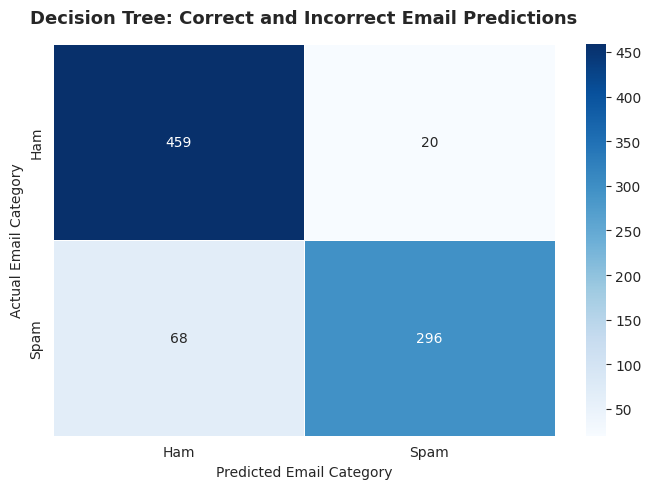

In [34]:
# Step 17: Train and Evaluate Decision Tree Classifier

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ---------------------------------------
# Part A: Create Decision Tree Model
# ---------------------------------------

tree_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=10,
    random_state=42
)

# ---------------------------------------
# Part B: Train the Model
# ---------------------------------------

tree_model.fit(X_train, y_train)

# ---------------------------------------
# Part C: Make Predictions
# ---------------------------------------

tree_predictions = tree_model.predict(X_test)

# ---------------------------------------
# Part D: Calculate Evaluation Metrics
# ---------------------------------------

tree_accuracy = accuracy_score(
    y_test, tree_predictions
)

tree_precision = precision_score(
    y_test, tree_predictions,
    zero_division=0
)

tree_recall = recall_score(
    y_test, tree_predictions,
    zero_division=0
)

tree_f1 = f1_score(
    y_test, tree_predictions,
    zero_division=0
)

# ---------------------------------------
# Part E: Compare All Four Models
# ---------------------------------------

model_comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision (Spam)",
        "Recall (Spam)",
        "F1-Score (Spam)"
    ],

    "Baseline": [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1
    ],

    "Logistic Regression": [
        logistic_accuracy,
        logistic_precision,
        logistic_recall,
        logistic_f1
    ],

    "Naive Bayes": [
        nb_accuracy,
        nb_precision,
        nb_recall,
        nb_f1
    ],

    "Decision Tree": [
        tree_accuracy,
        tree_precision,
        tree_recall,
        tree_f1
    ]
})

print("=== MODEL PERFORMANCE COMPARISON ===")

display(model_comparison_df.round(3))

# ---------------------------------------
# Part F: Classification Report
# ---------------------------------------

print("\n=== DECISION TREE CLASSIFICATION REPORT ===")

print(
    classification_report(
        y_test,
        tree_predictions,
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

# ---------------------------------------
# Part G: Confusion Matrix
# ---------------------------------------

cm_tree = confusion_matrix(
    y_test,
    tree_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"],
    linewidths=0.5
)

plt.title(
    "Decision Tree: Correct and Incorrect Email Predictions",
    fontsize=13,
    fontweight="bold",
    pad=15
)

plt.xlabel("Predicted Email Category")
plt.ylabel("Actual Email Category")

plt.tight_layout()
plt.show()

# # Step 18 – Decision Tree Feature Importance Analysis

In Step 17, our Decision Tree classifier achieved:
- Accuracy: 89.6%
- Precision (Spam): 93.7%
- Recall (Spam): 81.3%
- F1-score (Spam): 87.1%
Now we want to answer an important question:

Which of the 57 email features did the Decision Tree use most to classify Spam and Ham?

In this step, I will examine the feature importance scores from my trained Decision Tree model.

I will identify the 15 most important features and create a horizontal bar chart to visualize their contributions.

I will also compare the Decision Tree findings with the Logistic Regression feature importance results from Step 15.

This will help me understand whether both algorithms rely on similar email characteristics.

### Step 18 – Decision Tree Feature Importance Results

I analyzed the feature importance scores of my Decision Tree classifier to identify which email characteristics contributed most to spam classification.

The most important feature was `char_freq_$`, with an importance score of 0.454, followed by `word_freq_remove` (0.212) and `char_freq_!` (0.103). Together, these three features accounted for approximately 76.9% of the tree's total weighted impurity reduction.

Other important features included `word_freq_hp` (0.056), `capital_run_length_total` (0.050), and `word_freq_free` (0.039).

These findings suggest that monetary symbols, promotional language, and capitalization patterns play an important role in the Decision Tree's classification rules.

When comparing these results with Logistic Regression, I found that both models identified several similar predictors, including the dollar sign, the word "remove", and the terms "hp" and "george".

However, the models ranked these features differently because Logistic Regression uses standardized coefficients, while Decision Tree feature importance measures weighted reductions in Gini impurity.

Overall, this analysis demonstrates that the two classification algorithms identify overlapping patterns in the Spambase dataset, although their methods of measuring feature importance differ.

=== TOP 15 DECISION TREE FEATURES ===


,Feature,Importance
0,char_freq_$,0.4544
1,word_freq_remove,0.2121
2,char_freq_!,0.1026
3,word_freq_hp,0.0565
4,capital_run_length_total,0.0498
5,word_freq_free,0.0394
6,word_freq_george,0.0219
7,word_freq_edu,0.0169
8,word_freq_money,0.0154
9,capital_run_length_longest,0.0134



Number of features used by the tree: 15


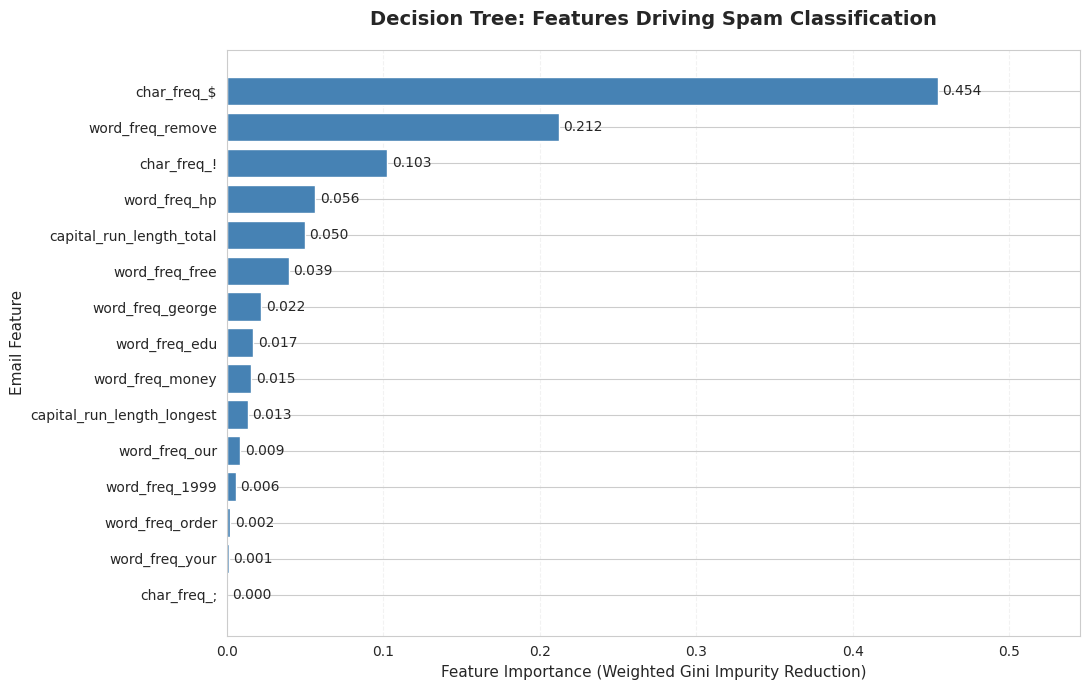

In [35]:
# Step 18: Decision Tree Feature Importance

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------
# Part A: Extract feature importance
# ---------------------------------------

# Get feature importance scores from trained tree
tree_importance = tree_model.feature_importances_

# Get feature names
feature_names = X_train.columns

# Create feature importance dataframe
tree_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree_importance
})

# Sort from highest to lowest importance
tree_importance_df = (
    tree_importance_df
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# ---------------------------------------
# Part B: Display Top 15 Features
# ---------------------------------------

print("=== TOP 15 DECISION TREE FEATURES ===")

display(
    tree_importance_df.head(15).round(4)
)

print("\nNumber of features used by the tree:",
      (tree_importance_df["Importance"] > 0).sum())

# ---------------------------------------
# Part C: Create Horizontal Bar Chart
# ---------------------------------------

top_15_tree = (
    tree_importance_df.head(15)
    .sort_values("Importance", ascending=True)
)

plt.figure(figsize=(11, 7))

bars = plt.barh(
    top_15_tree["Feature"],
    top_15_tree["Importance"],
    color="steelblue"
)

# Add importance labels
for bar, value in zip(
    bars,
    top_15_tree["Importance"]
):
    plt.text(
        value + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontsize=10
    )

# Add extra space for labels
max_importance = top_15_tree["Importance"].max()

plt.xlim(0, max_importance * 1.20)

plt.title(
    "Decision Tree: Features Driving Spam Classification",
    fontsize=14,
    fontweight="bold",
    pad=18
)

plt.xlabel(
    "Feature Importance (Weighted Gini Impurity Reduction)",
    fontsize=11
)

plt.ylabel("Email Feature", fontsize=11)

plt.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()
plt.show()

# Step 19 – Comparing the Performance of All Four Classification Models

We have successfully trained and evaluated four classification models using the Spambase dataset:
1. Baseline Classifier
2. Logistic Regression
3. Gaussian Naive Bayes
4. Decision Tree

Now we will create a visual comparison of all four models to identify which performs best at detecting spam emails.

In this step, I will compare the performance of four classification models using accuracy, precision, recall, and F1-score.

I will create a grouped bar chart with clearly labeled percentages to visualize the differences between models.

I will use these results to determine which classifier provides the best overall balance between identifying spam and avoiding incorrect classifications of legitimate emails.

=== FINAL MODEL PERFORMANCE COMPARISON ===


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Baseline,0.568,0.000,0.000,0.000
Logistic Regression,0.913,0.927,0.868,0.896
Naive Bayes,0.843,0.747,0.964,0.842
Decision Tree,0.896,0.937,0.813,0.871


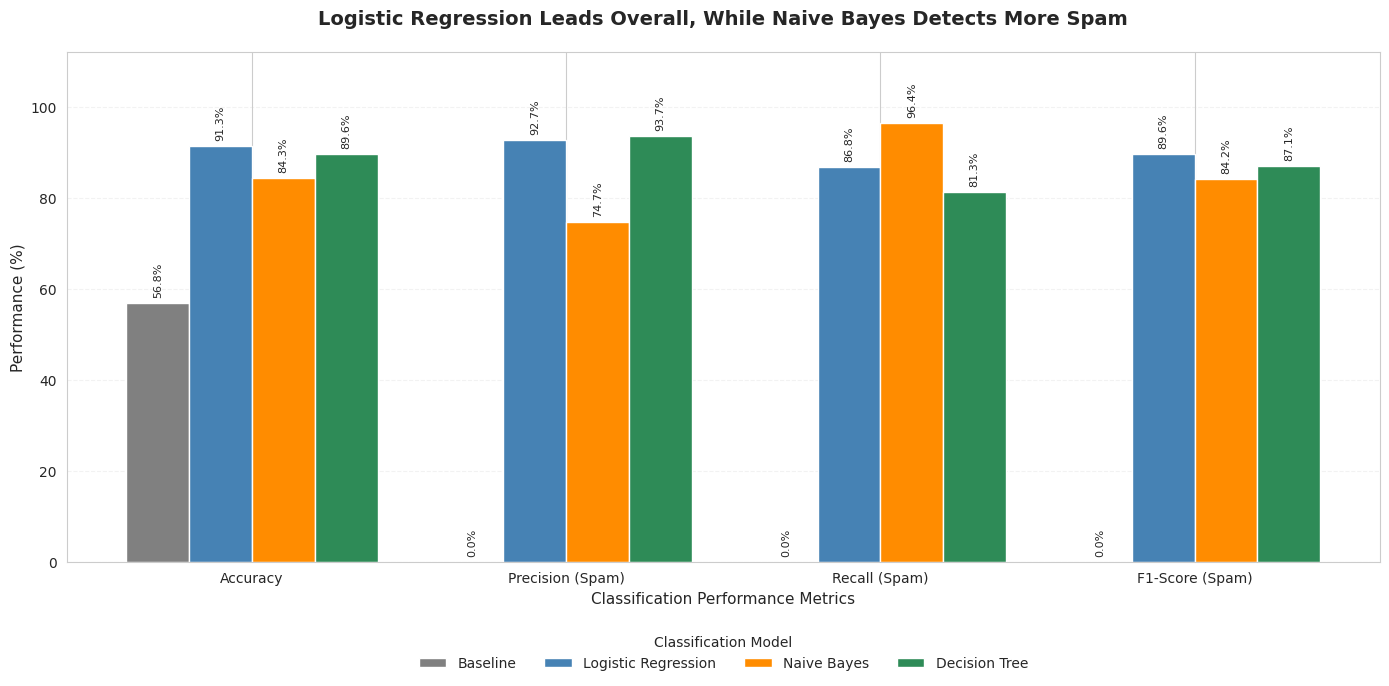

In [36]:
# Step 19: Compare Classification Model Performance

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# Part A: Create Model Comparison Table
# ---------------------------------------

model_results_df = pd.DataFrame({
    "Model": [
        "Baseline",
        "Logistic Regression",
        "Naive Bayes",
        "Decision Tree"
    ],

    "Accuracy": [
        baseline_accuracy,
        logistic_accuracy,
        nb_accuracy,
        tree_accuracy
    ],

    "Precision": [
        baseline_precision,
        logistic_precision,
        nb_precision,
        tree_precision
    ],

    "Recall": [
        baseline_recall,
        logistic_recall,
        nb_recall,
        tree_recall
    ],

    "F1-Score": [
        baseline_f1,
        logistic_f1,
        nb_f1,
        tree_f1
    ]
})

print("=== FINAL MODEL PERFORMANCE COMPARISON ===")

display(
    model_results_df.set_index("Model").round(3)
)

# ---------------------------------------
# Part B: Prepare Grouped Bar Chart
# ---------------------------------------

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

models = model_results_df["Model"].tolist()

x = np.arange(len(metrics))

bar_width = 0.20

colors = [
    "gray",
    "steelblue",
    "darkorange",
    "seagreen"
]

fig, ax = plt.subplots(figsize=(14, 7))

# ---------------------------------------
# Part C: Plot Each Model
# ---------------------------------------

for i, model in enumerate(models):

    values = (
        model_results_df.loc[
            model_results_df["Model"] == model,
            metrics
        ]
        .iloc[0]
        .values.astype(float)
        * 100
    )

    positions = x + (i - 1.5) * bar_width

    bars = ax.bar(
        positions,
        values,
        width=bar_width,
        label=model,
        color=colors[i]
    )

    # Add percentage labels above bars
    for bar, value in zip(bars, values):

        ax.annotate(
            f"{value:.1f}%",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=90
        )

# ---------------------------------------
# Part D: Format Chart
# ---------------------------------------

ax.set_title(
    "Logistic Regression Leads Overall, While Naive Bayes Detects More Spam",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Classification Performance Metrics",
    fontsize=11
)

ax.set_ylabel(
    "Performance (%)",
    fontsize=11
)

ax.set_xticks(x)

ax.set_xticklabels(
    ["Accuracy", "Precision (Spam)",
     "Recall (Spam)", "F1-Score (Spam)"],
    fontsize=10
)

ax.set_ylim(0, 112)

ax.legend(
    title="Classification Model",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4,
    frameon=False
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Accuracy: Measures the percentage of all emails correctly classified as Spam or Ham.

Precision: Measures how many emails predicted as Spam are actually Spam. Higher precision means fewer legitimate emails are incorrectly flagged.


Recall: Measures how many actual Spam emails the model successfully detects. Higher recall means fewer spam emails are missed.


F1-Score: Measures the balance between Precision and Recall using their harmonic mean. A higher F1-score indicates a better balance between detecting Spam and avoiding incorrect Spam predictions.

# Step 20 – ROC Curve and AUC Analysis for Spam Classification

We have completed Step 19, where we compared the performance of our four classification models.

Our results showed that Logistic Regression achieved the highest accuracy (91.3%) and F1-score (89.6%).

Now we will use ROC curves and AUC scores to evaluate how well the models distinguish Spam from Ham at different classification thresholds.

In this step, I will calculate the ROC curves and AUC scores for Logistic Regression, Naive Bayes, and Decision Tree.

I will visualize the three models on the same graph to compare their ability to distinguish Spam from Ham.

I will also identify which model has the highest ROC-AUC score.

What Is an ROC Curve?
ROC stands for Receiver Operating Characteristic.

An ROC curve shows how well a classification model separates two categories across different probability thresholds.

It compares:

- True Positive Rate (Recall): The proportion of actual Spam emails correctly detected.
- False Positive Rate: The proportion of actual Ham emails incorrectly classified as Spam.

The ROC curve helps us understand the trade-off between detecting more Spam and incorrectly flagging legitimate emails.

What Is AUC?
AUC stands for Area Under the Curve.

It summarizes the ROC curve into a single number between 0 and 1.

=== ROC-AUC MODEL COMPARISON ===


,Model,ROC-AUC
0,Logistic Regression,0.969
1,Naive Bayes,0.949
2,Decision Tree,0.931


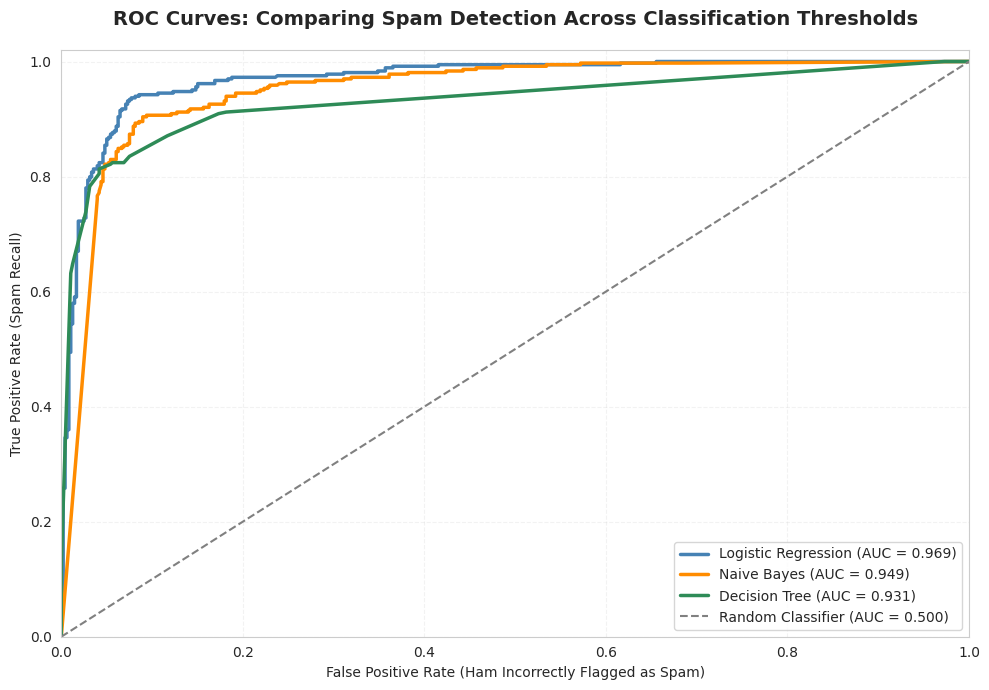

In [37]:
# Step 20: ROC Curve and AUC Comparison

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

# ---------------------------------------
# Part A: Get predicted Spam probabilities
# ---------------------------------------

# Probability of class 1 (Spam)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]
nb_prob = nb_model.predict_proba(X_test)[:, 1]
tree_prob = tree_model.predict_proba(X_test)[:, 1]

# ---------------------------------------
# Part B: Calculate ROC curves
# ---------------------------------------

fpr_log, tpr_log, _ = roc_curve(y_test, logistic_prob)
fpr_nb, tpr_nb, _ = roc_curve(y_test, nb_prob)
fpr_tree, tpr_tree, _ = roc_curve(y_test, tree_prob)

# ---------------------------------------
# Part C: Calculate AUC scores
# ---------------------------------------

auc_log = roc_auc_score(y_test, logistic_prob)
auc_nb = roc_auc_score(y_test, nb_prob)
auc_tree = roc_auc_score(y_test, tree_prob)

# Display AUC comparison
auc_results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Decision Tree"
    ],
    "ROC-AUC": [
        auc_log,
        auc_nb,
        auc_tree
    ]
})

auc_results_df = auc_results_df.sort_values(
    "ROC-AUC",
    ascending=False
)

print("=== ROC-AUC MODEL COMPARISON ===")
display(auc_results_df.round(3))

# ---------------------------------------
# Part D: Plot ROC curves
# ---------------------------------------

plt.figure(figsize=(10, 7))

plt.plot(
    fpr_log, tpr_log,
    label=f"Logistic Regression (AUC = {auc_log:.3f})",
    color="steelblue",
    linewidth=2.5
)

plt.plot(
    fpr_nb, tpr_nb,
    label=f"Naive Bayes (AUC = {auc_nb:.3f})",
    color="darkorange",
    linewidth=2.5
)

plt.plot(
    fpr_tree, tpr_tree,
    label=f"Decision Tree (AUC = {auc_tree:.3f})",
    color="seagreen",
    linewidth=2.5
)

# Random classifier reference line
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.500)"
)

# ---------------------------------------
# Part E: Format the chart
# ---------------------------------------

plt.title(
    "ROC Curves: Comparing Spam Detection Across Classification Thresholds",
    fontsize=14,
    fontweight="bold",
    pad=18
)

plt.xlabel("False Positive Rate (Ham Incorrectly Flagged as Spam)")
plt.ylabel("True Positive Rate (Spam Recall)")

plt.xlim(0, 1)
plt.ylim(0, 1.02)

plt.legend(
    loc="lower right",
    fontsize=10,
    frameon=True
)

plt.grid(
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()
plt.show()

# Step 20 – Interpretation of ROC Curve and AUC Results

Your ROC curve shows that Logistic Regression has the strongest overall ability to distinguish Spam from Ham, followed by Naive Bayes and Decision Tree.

All three models achieved ROC-AUC scores above 0.90, indicating excellent discrimination on our test dataset.

How Do We Interpret the ROC Curve?

graph shows three important patterns:

- Logistic Regression (blue): Its curve is generally closest to the upper-left corner, indicating strong spam detection at relatively low false positive rates.
- Naive Bayes (orange): Also performs well, although its ROC-AUC is slightly lower.
- Decision Tree (green): Achieves a strong AUC but ranks below the other two models.

The dashed diagonal line represents random ranking. All three curves are substantially above this line.

What Does an AUC of 0.969 Mean?
An ROC-AUC of 0.969 means that if we randomly select one Spam email and one Ham email from the test dataset, the Logistic Regression model has approximately a 96.9% probability of assigning a higher spam score to the Spam email, with ties receiving half credit.

It does not mean that the model classifies 96.9% of emails correctly.

# How Do We Interpret the ROC Curve?

graph shows three important patterns:

- Logistic Regression (blue): Its curve is generally closest to the upper-left corner, indicating strong spam detection at relatively low false positive rates.
- Naive Bayes (orange): Also performs well, although its ROC-AUC is slightly lower.
- Decision Tree (green): Achieves a strong AUC but ranks below the other two models.
The dashed diagonal line represents random ranking. All three curves are substantially above this line.

What Does an AUC of 0.969 Mean?
An ROC-AUC of 0.969 means that if we randomly select one Spam email and one Ham email from the test dataset, the Logistic Regression model has approximately a 96.9% probability of assigning a higher spam score to the Spam email, with ties receiving half credit.

It does not mean that the model classifies 96.9% of emails correctly.

=== 5-FOLD CROSS-VALIDATION RESULTS ===


,Model,Mean F1,F1 Std,Mean ROC-AUC,AUC Std
0,Logistic Regression,0.896,0.011,0.970,0.004
2,Decision Tree,0.866,0.015,0.924,0.004
1,Naive Bayes,0.808,0.012,0.944,0.005


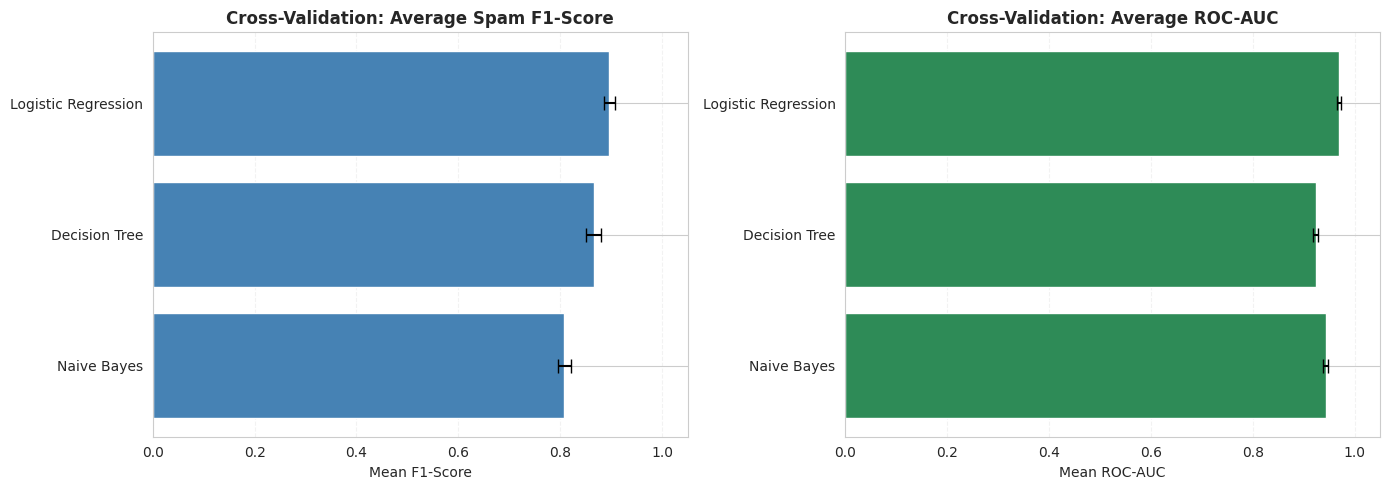

In [38]:
# Step 21: 5-Fold Cross-Validation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_validate
)

# ---------------------------------------
# Part A: Create groups for training data
# ---------------------------------------

# Identical predictor patterns receive the same group ID
train_groups = pd.factorize(
    pd.MultiIndex.from_frame(X_train)
)[0]

# ---------------------------------------
# Part B: Set up 5-fold cross-validation
# ---------------------------------------

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ---------------------------------------
# Part C: Select models
# ---------------------------------------

models = {
    "Logistic Regression": logistic_model,
    "Naive Bayes": nb_model,
    "Decision Tree": tree_model
}

# ---------------------------------------
# Part D: Evaluate each model
# ---------------------------------------

cv_results = []

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=train_groups,
        cv=cv,
        scoring={
            "F1": "f1",
            "ROC-AUC": "roc_auc"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "Mean F1": scores["test_F1"].mean(),
        "F1 Std": scores["test_F1"].std(),
        "Mean ROC-AUC": scores["test_ROC-AUC"].mean(),
        "AUC Std": scores["test_ROC-AUC"].std()
    })

# ---------------------------------------
# Part E: Display comparison table
# ---------------------------------------

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    "Mean F1",
    ascending=False
)

print("=== 5-FOLD CROSS-VALIDATION RESULTS ===")

display(cv_results_df.round(3))

# ---------------------------------------
# Part F: Visualize cross-validation results
# ---------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# F1-score comparison
axes[0].barh(
    cv_results_df["Model"],
    cv_results_df["Mean F1"],
    xerr=cv_results_df["F1 Std"],
    color="steelblue",
    capsize=5
)

axes[0].set_title(
    "Cross-Validation: Average Spam F1-Score",
    fontweight="bold"
)

axes[0].set_xlabel("Mean F1-Score")
axes[0].set_xlim(0, 1.05)
axes[0].invert_yaxis()

# ROC-AUC comparison
axes[1].barh(
    cv_results_df["Model"],
    cv_results_df["Mean ROC-AUC"],
    xerr=cv_results_df["AUC Std"],
    color="seagreen",
    capsize=5
)

axes[1].set_title(
    "Cross-Validation: Average ROC-AUC",
    fontweight="bold"
)

axes[1].set_xlabel("Mean ROC-AUC")
axes[1].set_xlim(0, 1.05)
axes[1].invert_yaxis()

for ax in axes:
    ax.grid(axis="x", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# Step 21 – Interpretation of Cross-Validation Results

cross-validation chart shows that Logistic Regression continues to perform best overall, followed by Decision Tree and Naive Bayes based on F1-score.



# Step 22 – Final Conclusions and Business Recommendations

We have reached the final step of our DATA 620 Spambase Classification Project.

We completed data preprocessing, exploratory data analysis, feature importance analysis, model training, performance evaluation, ROC-AUC analysis, and cross-validation.

Now we will summarize our findings and explain their practical significance.

## Conclusion and Business Recommendations

### Project Overview

The objective of my project was to classify emails as spam or legitimate using machine learning techniques and identify the numerical features that contribute most strongly to spam detection.

I used the UCI Spambase dataset, which originally contained 4,601 observations and 57 numerical predictors representing word frequencies, character frequencies, and capitalization patterns.

### Data Preparation and Exploratory Analysis

I examined the dataset for missing values, duplicate records, and conflicting labels. I identified 391 exact duplicate rows and removed them, leaving 4,210 observations for analysis.

I explored the numerical features using descriptive statistics, histograms, group comparisons, and correlation analysis.

The exploratory analysis showed that spam emails generally contained higher frequencies of promotional words, monetary symbols, and capitalization patterns.

I used a group-aware train/test split to reduce data leakage by keeping identical numerical feature patterns together.

### Classification Model Results

I trained and evaluated a baseline classifier, Logistic Regression, Gaussian Naive Bayes, and Decision Tree.

The baseline model achieved 56.8% accuracy but failed to identify any spam emails.

Logistic Regression achieved the strongest overall performance, with 91.3% accuracy, 92.7% precision, 86.8% recall, an F1-score of 89.6%, and a ROC-AUC of 0.969.

Gaussian Naive Bayes achieved the highest spam recall at 96.4%, demonstrating its ability to identify most spam emails. However, it also incorrectly classified more legitimate emails as spam.

Decision Tree achieved 89.6% accuracy and the highest spam precision at 93.7%, but its recall was lower than the other two trained classifiers.

### Feature Importance

I examined feature importance using standardized Logistic Regression coefficients and Decision Tree impurity-based importance scores.

Both models identified monetary symbols and promotional language as important predictors of spam. Features such as `char_freq_$` and `word_freq_remove` were particularly influential.

Other features, including `word_freq_hp` and `word_freq_george`, were associated with legitimate emails.

These findings indicate that machine learning models can use word-frequency, character-frequency, and capitalization patterns to distinguish spam from ham.

### Cross-Validation

I performed 5-fold cross-validation to assess the consistency of the classification models.

Logistic Regression achieved the highest average F1-score and ROC-AUC across the validation folds. These findings supported the results from the original testing dataset.

### Business Recommendations

Based on my findings, I recommend Logistic Regression as the leading model for further development because it achieved the best overall balance between classification accuracy, precision, recall, and ROC-AUC.

For a practical email filtering system, minimizing false positives is particularly important because legitimate emails may contain important personal or business communications.

Future improvements could include optimizing the classification threshold, tuning model hyperparameters, testing on more recent email datasets, and monitoring performance over time.

### Limitations and Future Work

The Spambase dataset contains precomputed numerical features rather than the original email text. Therefore, I could not directly apply advanced natural language processing techniques such as tokenization, part-of-speech tagging, or parsing to the underlying messages.

The dataset also contains some conflicting feature patterns and may not fully represent modern spam behavior.

Additionally, repeated comparisons using the same testing dataset may influence model selection, so future work should include evaluation on a new independent dataset.

### Final Conclusion

Overall, my analysis demonstrates that supervised machine learning can effectively distinguish spam from legitimate emails using numerical text-related features.

Logistic Regression emerged as the strongest overall model, while Naive Bayes and Decision Tree demonstrated different strengths in recall and precision.

The project highlights the importance of evaluating multiple classification metrics, examining feature importance, preventing data leakage, and using cross-validation to support reliable model selection.